# Phishing URL Detection — Data Visualization Case Study

**Course:** Data Visualization (23CSE353)  
**Name:** Somisetty Veda Sai · **Register No.:** CB.SC.U4CSE24448 · **Section:** E  
**Dataset:** PhiUSIIL Phishing URL Dataset — UCI Machine Learning Repository  
**Notebook scope:** Reproducible data-quality assessment, justified preparation, 30 static visualizations, and one interactive Plotly visualization.

## Case study question
Which observable URL and webpage characteristics differ between the legitimate and phishing records in the PhiUSIIL dataset, and how can those differences be communicated responsibly through visualizations?

## Analytical objectives
1. Describe the target-class distribution and audit basic data quality before analysis.
2. Compare URL-structure, domain/TLD, page-content and metadata features across the two classes.
3. Identify associations that may be useful for investigation while avoiding causal claims or treating a dataset-specific feature as a guaranteed production signal.
4. Demonstrate ethical chart design using a deliberately truncated bar chart and its corrected version.

**Label definition (UCI):** `label = 1` means *legitimate*; `label = 0` means *phishing*. This mapping is used consistently in the code and chart legends.

**Dataset source:** Prasad, A. & Chandra, S. (2024). *PhiUSIIL Phishing URL (Website).* UCI Machine Learning Repository. https://doi.org/10.1016/j.cose.2023.103545. Dataset page: https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+website+dataset

**Reproducibility:** Keep the supplied CSV in the same folder as this notebook, or set `DATA_PATH` in the setup cell. All chart samples use fixed random seeds. Derived bins are for analysis only; the original CSV is not overwritten.

**Assessment note:** Matplotlib, Seaborn and Plotly are demonstrated here. The course rubric separately requires a native Tableau or Power BI interactive dashboard and its project/source file. This notebook does not substitute for that native dashboard deliverable.


## 0. Setup — Imports, data path and visualization style

The notebook uses only the supplied PhiUSIIL dataset. Matplotlib is used for general charts, Seaborn for statistical visualizations, and Plotly for a browser-interactive chart. The class labels are fixed to the UCI definition above.

In [2]:
# Core data and visualization libraries
from pathlib import Path
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import ticker
from matplotlib.colors import ListedColormap
import seaborn as sns
from scipy import stats as scipy_stats
from scipy.stats import gaussian_kde
from scipy.interpolate import griddata
import matplotlib.tri as tri
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 — registers 3D projection
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Suppress only noisy deprecation/future warnings; keep meaningful runtime warnings visible.
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning, module='seaborn')

# Deterministic sampling and global visual style
RANDOM_STATE = 42
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.0)
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 13,
                     'axes.labelsize': 11, 'legend.framealpha': 0.85,
                     'savefig.dpi': 140})

COLOR_LEGIT = '#2878B5'   # blue = Legitimate (label=1)
COLOR_PHISH = '#D9534F'   # red  = Phishing (label=0)
PALETTE = {1: COLOR_LEGIT, 0: COLOR_PHISH}
LABEL_NAMES = {1: 'Legitimate', 0: 'Phishing'}

# Resolve the uploaded filename as well as the canonical UCI filename.
DATA_CANDIDATES = [
    Path('PhiUSIIL_Phishing_URL_Dataset.csv'),
    Path('PhiUSIIL_Phishing_URL_Dataset(2).csv'),
    Path('/mnt/data/PhiUSIIL_Phishing_URL_Dataset(2).csv'),
    Path('/mnt/data/PhiUSIIL_Phishing_URL_Dataset.csv'),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Dataset not found. Put PhiUSIIL_Phishing_URL_Dataset.csv beside this notebook or update DATA_PATH.')

print(f'Setup complete. Dataset: {DATA_PATH.resolve()}')
print('Class mapping: 0 = Phishing | 1 = Legitimate')


Setup complete. Dataset: C:\Users\ASUS\Downloads\PhiUSIIL_Phishing_URL_Dataset.csv
Class mapping: 0 = Phishing | 1 = Legitimate


## 1. Dataset Loading & Exploration

In [3]:
df_raw = pd.read_csv(DATA_PATH, low_memory=False)
df = df_raw.copy()
print(f'Original dataset shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns')
print(f'Memory footprint (dataframe): {df_raw.memory_usage(deep=True).sum()/1024**2:,.1f} MiB')
display(df_raw.head())


Original dataset shape: 235,795 rows × 56 columns
Memory footprint (dataframe): 166.2 MiB


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


In [3]:
print('=== Data types ===')
display(df_raw.dtypes.rename('dtype').to_frame())
print('Missing cells in entire source: {int(df_raw.isna().sum().sum()):,}')
missing = df_raw.isna().sum().rename('missing_count').to_frame()
missing = missing[missing['missing_count'] > 0]
print('Columns with missing values:')
display(missing if not missing.empty else pd.DataFrame({'status':['No missing values detected in the supplied CSV']}))


=== Data types ===


,dtype
FILENAME,object
URL,object
URLLength,int64
Domain,object
DomainLength,int64
IsDomainIP,int64
TLD,object
URLSimilarityIndex,float64
CharContinuationRate,float64
TLDLegitimateProb,float64


Missing cells in entire source: {int(df_raw.isna().sum().sum()):,}
Columns with missing values:


,status
0,No missing values detected in the supplied CSV


In [4]:
num_feats = ['URLLength','LineOfCode','NoOfImage','NoOfExternalRef',
             'URLSimilarityIndex','CharContinuationRate','TLDLegitimateProb',
             'URLCharProb','NoOfSubDomain','LetterRatioInURL','DomainTitleMatchScore']
display(df_raw[num_feats].describe().T.round(3))


,count,mean,std,min,25%,50%,75%,max
URLLength,235795.0,34.573,41.314,13.000,23.000,27.000,34.000,6097.000
LineOfCode,235795.0,1141.900,3419.951,2.000,18.000,429.000,1277.000,442666.000
NoOfImage,235795.0,26.076,79.412,0.000,0.000,8.000,29.000,8956.000
NoOfExternalRef,235795.0,49.263,161.027,0.000,1.000,10.000,57.000,27516.000
URLSimilarityIndex,235795.0,78.431,28.976,0.156,57.025,100.000,100.000,100.000
CharContinuationRate,235795.0,0.846,0.217,0.000,0.680,1.000,1.000,1.000
TLDLegitimateProb,235795.0,0.260,0.252,0.000,0.006,0.080,0.523,0.523
URLCharProb,235795.0,0.056,0.011,0.001,0.051,0.058,0.063,0.091
NoOfSubDomain,235795.0,1.165,0.601,0.000,1.000,1.000,1.000,10.000
LetterRatioInURL,235795.0,0.516,0.123,0.000,0.435,0.519,0.594,0.926


In [5]:
vc = df_raw['label'].value_counts().sort_index()
class_summary = pd.DataFrame({
    'class': [LABEL_NAMES[int(k)] for k in vc.index],
    'count': vc.values,
    'percentage': (vc.values / len(df_raw) * 100).round(2)
})
display(class_summary)
print(f'Total records: {len(df_raw):,}')


,class,count,percentage
0,Phishing,100945,42.81
1,Legitimate,134850,57.19


Total records: 235,795


## 2. Data Cleaning & Preprocessing

Cleaning decisions are kept conservative because the assignment is a visualization case study. The source contains no missing cells and no exact duplicate rows, so there is no evidence-based reason to impute or delete records. `FILENAME` is excluded from the analysis because UCI documents it as an ignorable metadata column. Repeated URLs and repeated domains are audited; domain repetition is retained because many URLs may belong to one domain, and repeated URLs are checked for conflicting class labels before any deduplication decision.

In [6]:
# Preserve df_raw as the untouched source copy; drop only the documented metadata field from analysis.
if 'FILENAME' in df.columns:
    df = df.drop(columns=['FILENAME'])
print(f'Analysis dataframe shape after excluding FILENAME: {df.shape[0]:,} rows × {df.shape[1]} columns')
print('No source file has been overwritten.')


Analysis dataframe shape after excluding FILENAME: 235,795 rows × 55 columns
No source file has been overwritten.


In [7]:
duplicate_rows = int(df.duplicated().sum())
duplicate_url_rows = int(df.duplicated(subset=['URL']).sum())
duplicate_domain_rows = int(df.duplicated(subset=['Domain']).sum())
url_label_nunique = df.groupby('URL', dropna=False)['label'].nunique()
conflicting_url_groups = int((url_label_nunique > 1).sum())
quality_summary = pd.DataFrame({
    'check': ['Missing cells', 'Exact duplicate rows', 'Repeated URL rows beyond first occurrence',
              'Repeated domain rows beyond first occurrence', 'URL groups with conflicting labels'],
    'result': [int(df.isna().sum().sum()), duplicate_rows, duplicate_url_rows,
               duplicate_domain_rows, conflicting_url_groups]
})
display(quality_summary)
print('Decision: retain repeated URLs/domains for descriptive EDA; no exact duplicate rows were found and repeated URL groups do not have conflicting labels.')
print('For a future predictive model, use a group-aware split by URL/domain to limit train-test overlap.')


,check,result
0,Missing cells,0
1,Exact duplicate rows,0
2,Repeated URL rows beyond first occurrence,425
3,Repeated domain rows beyond first occurrence,15709
4,URL groups with conflicting labels,0


Decision: retain repeated URLs/domains for descriptive EDA; no exact duplicate rows were found and repeated URL groups do not have conflicting labels.
For a future predictive model, use a group-aware split by URL/domain to limit train-test overlap.


In [8]:
# Scaling demonstration only: fit on a larger, reproducible sample, then display five rows.
# The scaled values are NOT written back to df and do not change the source dataset.
scale_cols = ['URLLength', 'LineOfCode', 'NoOfImage', 'NoOfExternalRef']
scale_sample = df[scale_cols].sample(n=min(1000, len(df)), random_state=RANDOM_STATE)
std_values = StandardScaler().fit_transform(scale_sample)
mm_values = MinMaxScaler().fit_transform(scale_sample)
print('Original sample (first five rows):')
display(scale_sample.head().reset_index(drop=True))
print('StandardScaler transform (first five rows):')
display(pd.DataFrame(std_values, columns=[c+'_std' for c in scale_cols]).head().round(3))
print('MinMaxScaler transform (first five rows):')
display(pd.DataFrame(mm_values, columns=[c+'_minmax' for c in scale_cols]).head().round(3))


Original sample (first five rows):


,URLLength,LineOfCode,NoOfImage,NoOfExternalRef
0,24,999,47,115
1,59,116,0,1
2,385,14,0,1
3,19,9,0,1
4,35,1213,33,2


StandardScaler transform (first five rows):


,URLLength_std,LineOfCode_std,NoOfImage_std,NoOfExternalRef_std
0,-0.296,-0.051,0.394,0.626
1,0.736,-0.465,-0.472,-0.483
2,10.345,-0.513,-0.472,-0.483
3,-0.443,-0.515,-0.472,-0.483
4,0.028,0.049,0.136,-0.473


MinMaxScaler transform (first five rows):


,URLLength_minmax,LineOfCode_minmax,NoOfImage_minmax,NoOfExternalRef_minmax
0,0.014,0.025,0.066,0.077
1,0.064,0.003,0.000,0.001
2,0.524,0.000,0.000,0.001
3,0.007,0.000,0.000,0.001
4,0.030,0.030,0.046,0.001


In [9]:
# Ordered categories use left-closed intervals so labels are unambiguous: [0,20), [20,30), ...
length_bins = [0, 20, 30, 50, 100, np.inf]
length_labels = ['Very short (<20)', 'Short (20–29)', 'Medium (30–49)', 'Long (50–99)', 'Very long (≥100)']
df['URLLength_bin'] = pd.cut(df['URLLength'], bins=length_bins, labels=length_labels,
                             right=False, include_lowest=True, ordered=True)
print('URL length bins (derived for analysis only):')
display(df['URLLength_bin'].value_counts(sort=False).rename('count').to_frame())


URL length bins (derived for analysis only):


,count
URLLength_bin,
Very short (<20),12961
Short (20–29),129295
Medium (30–49),69832
Long (50–99),18731
Very long (≥100),4976


## 3. Matplotlib Visualizations
### Plot 1 — Class Distribution Bar Chart

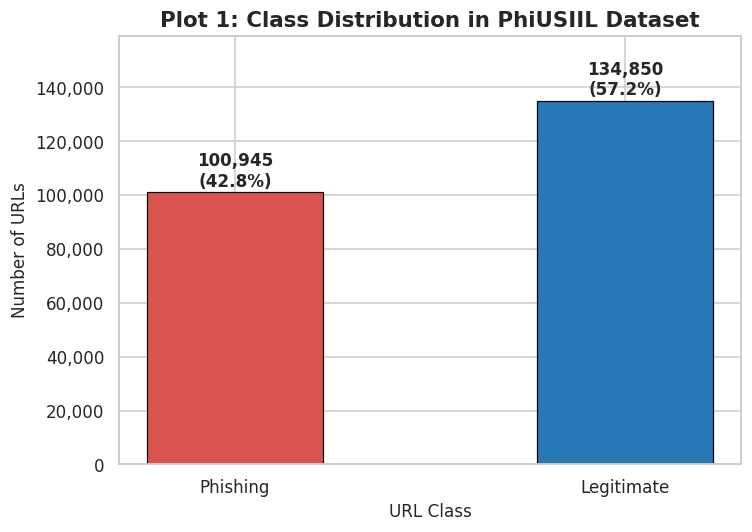

In [10]:
counts = df['label'].value_counts().sort_index()
labels_txt = [LABEL_NAMES[i] for i in counts.index]
colors     = [PALETTE[i]     for i in counts.index]

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(labels_txt, counts.values, color=colors, width=0.45,
              edgecolor='black', linewidth=0.8)
for bar, cnt in zip(bars, counts.values):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+800,
            f'{cnt:,}\n({cnt/len(df)*100:.1f}%)',
            ha='center', va='bottom', fontsize=11, fontweight='bold')
ax.set_title('Plot 1: Class Distribution in PhiUSIIL Dataset',
             fontsize=14, fontweight='bold')
ax.set_xlabel('URL Class'); ax.set_ylabel('Number of URLs')
ax.set_ylim(0, counts.max()*1.18)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x,_: f'{int(x):,}'))
plt.tight_layout(); plt.savefig('plot_01.png', dpi=110, bbox_inches='tight')
plt.show()


**Interpretation:**
The dataset has **134,850 Legitimate URLs (57.2%)** and **100,945 Phishing URLs (42.8%)** — a moderate imbalance of ~1.34×. A naive classifier that always predicts 'Legitimate' would score 57.2% accuracy, so imbalance-aware metrics (precision, recall, F1) are essential.


### Plot 2 — Pie Chart: Class Proportions

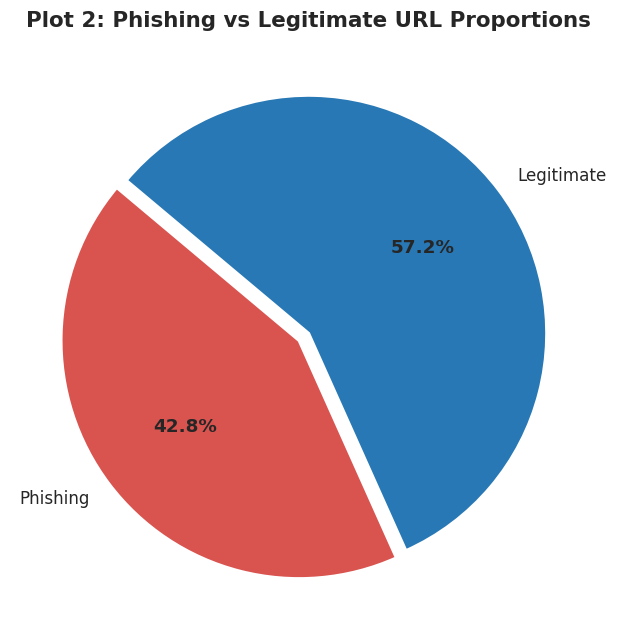

In [11]:
counts = df['label'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 6))
wedges, texts, auts = ax.pie(
    counts.values,
    labels=[LABEL_NAMES[i] for i in counts.index],
    autopct='%1.1f%%',
    colors=[PALETTE[i] for i in counts.index],
    startangle=140, explode=(0.05, 0),
    wedgeprops=dict(edgecolor='white', linewidth=2))
for at in auts: at.set_fontsize(12); at.set_fontweight('bold')
ax.set_title('Plot 2: Phishing vs Legitimate URL Proportions',
             fontsize=14, fontweight='bold')
plt.tight_layout(); plt.savefig('plot_02.png', dpi=110, bbox_inches='tight')
plt.show()


**Interpretation:**
The pie chart makes proportional comparison instant. With 57.2% vs 42.8%, the dataset is not severely imbalanced (unlike real-world 1:100 ratios), but the 14.4-point gap still demands stratified sampling and balanced evaluation metrics.


### Plot 3 — Histogram + KDE: URLLength Distribution

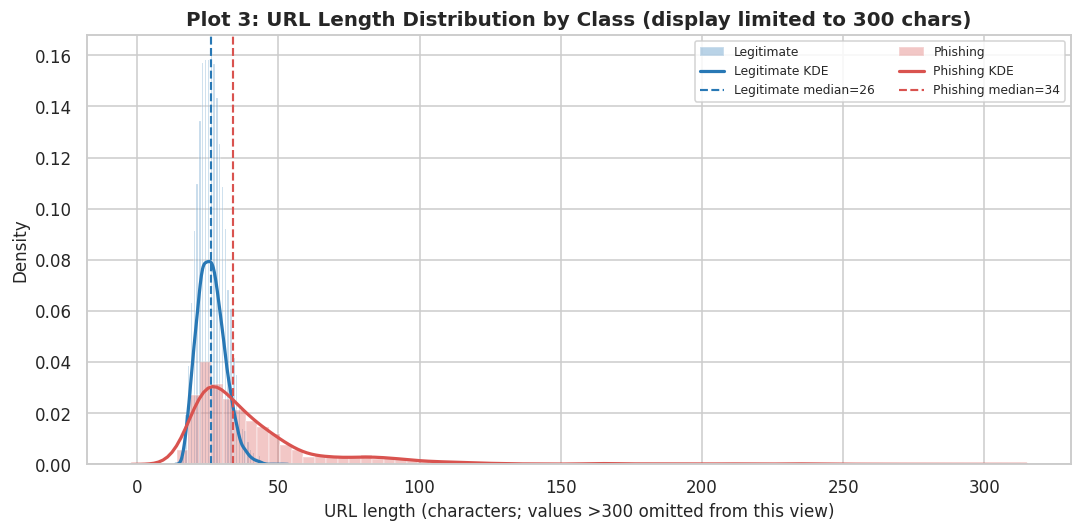

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
clip_val = 300
for lbl, color in PALETTE.items():
    raw = df.loc[df['label']==lbl, 'URLLength']
    visible = raw[raw <= clip_val]
    data = visible.sample(n=min(7000, len(visible)), random_state=RANDOM_STATE)
    ax.hist(data, bins=70, density=True, alpha=0.32, color=color, label=LABEL_NAMES[lbl])
    sns.kdeplot(data=data, ax=ax, color=color, linewidth=2.1, label=f'{LABEL_NAMES[lbl]} KDE')
    med = raw.median()
    ax.axvline(med, color=color, ls='--', lw=1.4, label=f'{LABEL_NAMES[lbl]} median={med:.0f}')
ax.set_title('Plot 3: URL Length Distribution by Class (display limited to 300 chars)', fontweight='bold')
ax.set_xlabel('URL length (characters; values >300 omitted from this view)'); ax.set_ylabel('Density')
ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.savefig('plot_03.png', bbox_inches='tight'); plt.show()


**Interpretation:** The full-data medians are **34 characters for phishing** and **26 for legitimate** URLs. The distribution is right-skewed, so the mean is influenced by long URLs. Values above 300 characters are intentionally omitted from this view rather than piled at the boundary; the chart is a readable view of the central distribution, not a claim that longer URLs do not exist.

### Plot 4 — Histogram: LineOfCode (log scale)

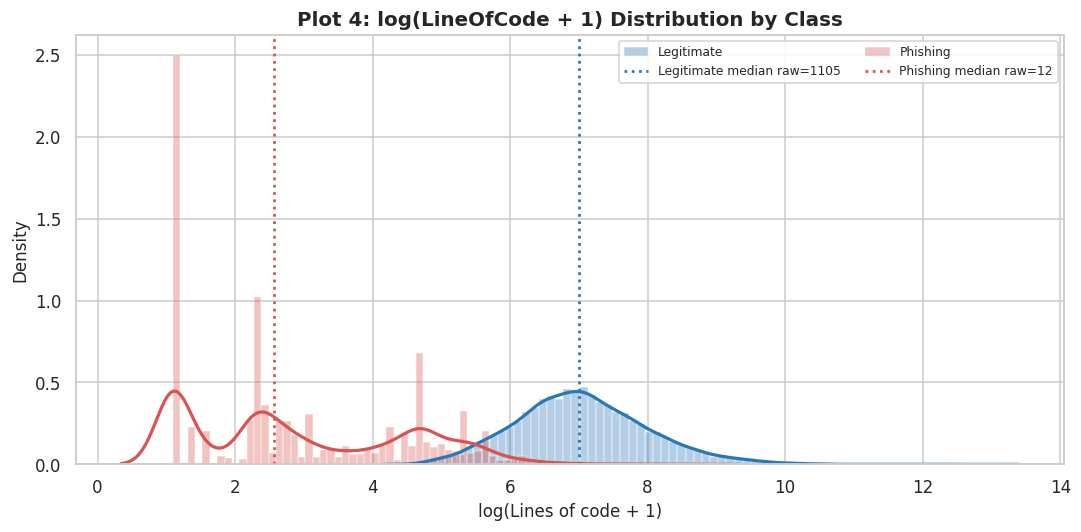

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))
for lbl, color in PALETTE.items():
    raw = df.loc[df['label']==lbl, 'LineOfCode']
    data = np.log1p(raw.sample(n=min(10000, len(raw)), random_state=RANDOM_STATE))
    ax.hist(data, bins=70, density=True, alpha=0.35, color=color, label=LABEL_NAMES[lbl])
    sns.kdeplot(data=data, ax=ax, color=color, linewidth=2.1)
    med_raw = raw.median()
    ax.axvline(np.log1p(med_raw), color=color, ls=':', lw=1.8,
               label=f'{LABEL_NAMES[lbl]} median raw={med_raw:.0f}')
ax.set_title('Plot 4: log(LineOfCode + 1) Distribution by Class', fontweight='bold')
ax.set_xlabel('log(Lines of code + 1)'); ax.set_ylabel('Density'); ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.savefig('plot_04.png', bbox_inches='tight'); plt.show()


**Interpretation:** On the full dataset, the median `LineOfCode` is **12 for phishing** and **1,105 for legitimate** records. The logarithmic axis makes the strongly right-skewed distribution readable; the dataset also contains very large values (maximum 442,666). The median gap is large in this sample, but it is not a validated measure of predictive performance.

### Plot 5 — Histogram: NoOfImage Distribution

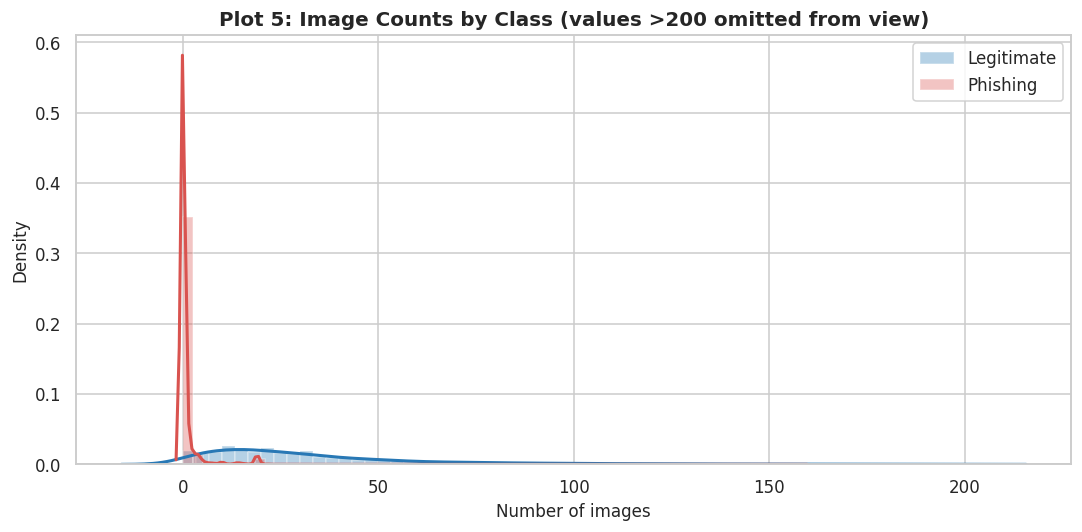

In [14]:
clip_img = 200
fig, ax = plt.subplots(figsize=(10, 5))
for lbl, color in PALETTE.items():
    raw = df.loc[df['label']==lbl, 'NoOfImage']
    visible = raw[raw <= clip_img]
    data = visible.sample(n=min(10000, len(visible)), random_state=RANDOM_STATE)
    ax.hist(data, bins=60, density=True, alpha=0.34, color=color, label=LABEL_NAMES[lbl])
    sns.kdeplot(data=data, ax=ax, color=color, linewidth=2.0)
ax.set_title('Plot 5: Image Counts by Class (values >200 omitted from view)', fontweight='bold')
ax.set_xlabel('Number of images'); ax.set_ylabel('Density'); ax.legend()
plt.tight_layout(); plt.savefig('plot_05.png', bbox_inches='tight'); plt.show()


**Interpretation:** The median `NoOfImage` count is **0 for phishing** and **25 for legitimate** records. The distributions differ, though values overlap and both classes contain pages with few or many images. This is a descriptive association in the supplied dataset; it does not establish why a page has a particular image count or make image count a reliable standalone security rule.

### Plot 6 — Grouped Bar Chart: Top-15 TLDs

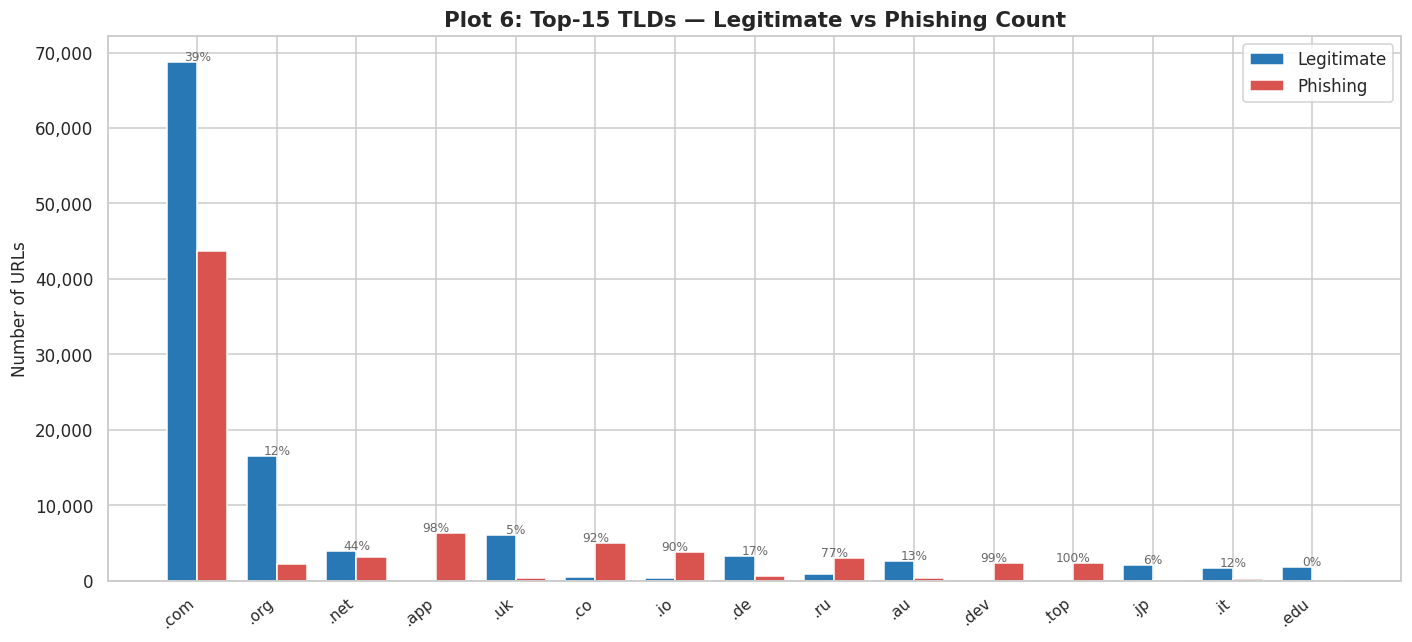

In [15]:
tld_class = df.groupby(['TLD','label']).size().unstack(fill_value=0)
tld_class.columns = ['Phishing','Legitimate']
tld_class['Total']    = tld_class.sum(axis=1)
tld_class['PhishPct'] = tld_class['Phishing'] / tld_class['Total']
top15 = tld_class.nlargest(15, 'Total')

x = np.arange(len(top15)); w = 0.38
fig, ax = plt.subplots(figsize=(13, 6))
ax.bar(x-w/2, top15['Legitimate'], width=w, color=COLOR_LEGIT,
       label='Legitimate', edgecolor='white')
ax.bar(x+w/2, top15['Phishing'],   width=w, color=COLOR_PHISH,
       label='Phishing',   edgecolor='white')
ax.set_xticks(x)
ax.set_xticklabels([f'.{t}' for t in top15.index], rotation=40, ha='right', fontsize=10)
ax.set_title('Plot 6: Top-15 TLDs — Legitimate vs Phishing Count',
             fontsize=14, fontweight='bold')
ax.set_ylabel('Number of URLs')
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x,_: f'{int(x):,}'))
ax.legend()
for xi, (tld, row) in zip(x, top15.iterrows()):
    ax.text(xi, max(row['Legitimate'], row['Phishing'])+200,
            f"{row['PhishPct']*100:.0f}%", ha='center', fontsize=8, color='dimgray')
plt.tight_layout(); plt.savefig('plot_06.png', dpi=110, bbox_inches='tight')
plt.show()


**Interpretation:** `.com` is the most frequent suffix in the sample, but frequency and class composition are different questions. Rates for uncommon TLDs are sensitive to sample size. TLD-level differences describe this dataset and should be used as one investigative signal—not as a blanket blocklist or a universal statement about a suffix.

### Plot 7 — Stacked Bar: Phishing-Dominated TLDs

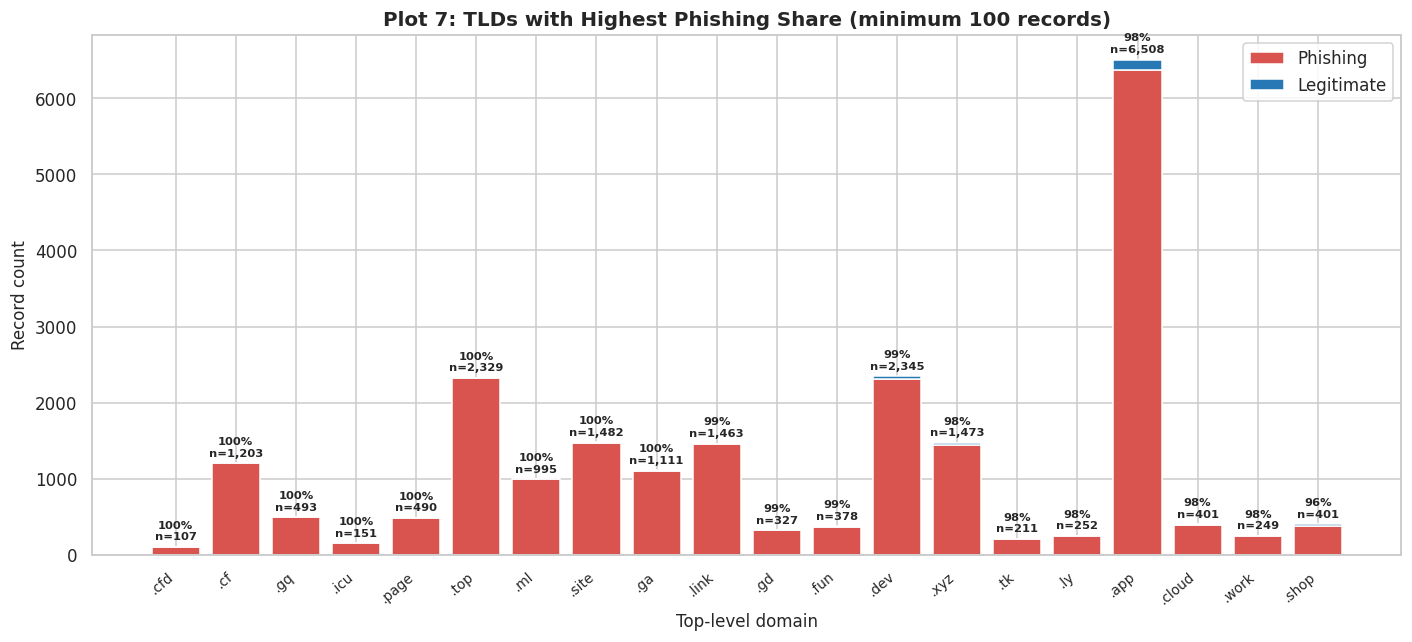

In [16]:
tld_rel = tld_class[tld_class['Total'] >= 100].copy()
tld_sorted = tld_rel.sort_values('PhishPct', ascending=False).head(20)
fig, ax = plt.subplots(figsize=(13, 6))
x = np.arange(len(tld_sorted))
ax.bar(x, tld_sorted['Phishing'], label='Phishing', color=COLOR_PHISH, edgecolor='white')
ax.bar(x, tld_sorted['Legitimate'], bottom=tld_sorted['Phishing'], label='Legitimate', color=COLOR_LEGIT, edgecolor='white')
ax.set_xticks(x)
ax.set_xticklabels([f'.{t}' for t in tld_sorted.index], rotation=40, ha='right', fontsize=9)
ax.set_title('Plot 7: TLDs with Highest Phishing Share (minimum 100 records)', fontweight='bold')
ax.set_xlabel('Top-level domain'); ax.set_ylabel('Record count'); ax.legend()
for i, (tld, row) in enumerate(tld_sorted.iterrows()):
    ax.text(i, row['Total']+max(tld_sorted['Total'])*0.01, f"{row['PhishPct']*100:.0f}%\nn={int(row['Total']):,}",
            ha='center', va='bottom', fontsize=7.5, fontweight='bold')
plt.tight_layout(); plt.savefig('plot_07.png', bbox_inches='tight'); plt.show()


**Interpretation:** The figure ranks suffixes represented by at least 100 records in this dataset. Some suffixes show very high phishing shares, while others have lower shares; the `n=` annotations expose the support behind each rate. These are descriptive sample associations and do not establish that a TLD causes phishing.

### Plot 8 — Annotated Histogram: URLSimilarityIndex

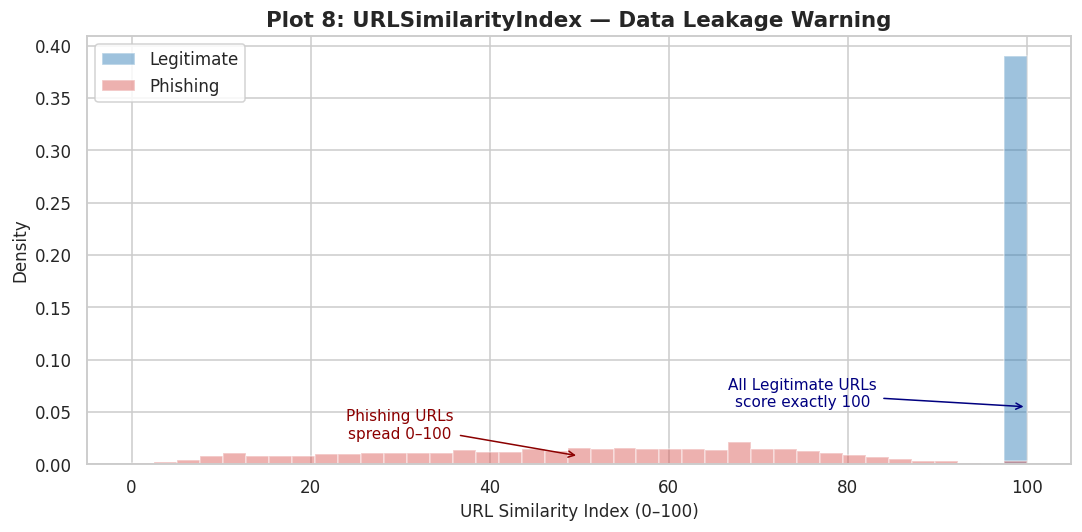

In [17]:
bins = np.linspace(0, 100, 40)
fig, ax = plt.subplots(figsize=(10, 5))
for lbl, color in PALETTE.items():
    ax.hist(df.loc[df['label']==lbl,'URLSimilarityIndex'],
            bins=bins, density=True, alpha=0.45, color=color,
            label=LABEL_NAMES[lbl])
ax.annotate('All Legitimate URLs\nscore exactly 100',
            xy=(100, 0.055), xytext=(75, 0.055),
            arrowprops=dict(arrowstyle='->', color='navy'),
            color='navy', fontsize=10, ha='center')
ax.annotate('Phishing URLs\nspread 0–100',
            xy=(50, 0.008), xytext=(30, 0.025),
            arrowprops=dict(arrowstyle='->', color='darkred'),
            color='darkred', fontsize=10, ha='center')
ax.set_title('Plot 8: URLSimilarityIndex — Data Leakage Warning',
             fontsize=14, fontweight='bold')
ax.set_xlabel('URL Similarity Index (0–100)'); ax.set_ylabel('Density')
ax.legend()
plt.tight_layout(); plt.savefig('plot_08.png', dpi=110, bbox_inches='tight')
plt.show()


**Interpretation and caution:** In this supplied dataset, every legitimate record has `URLSimilarityIndex = 100`, while phishing records span a wider range (median ≈51.4). This is a very strong class-aligned pattern. The chart alone does **not** prove how the feature was computed or that it is leakage. Before any predictive-model use, check the source definition and confirm that the feature could be computed at prediction time without using ground-truth labels or post-label information.

### Plot 9 — Line Chart: Normalised Feature Means by Class

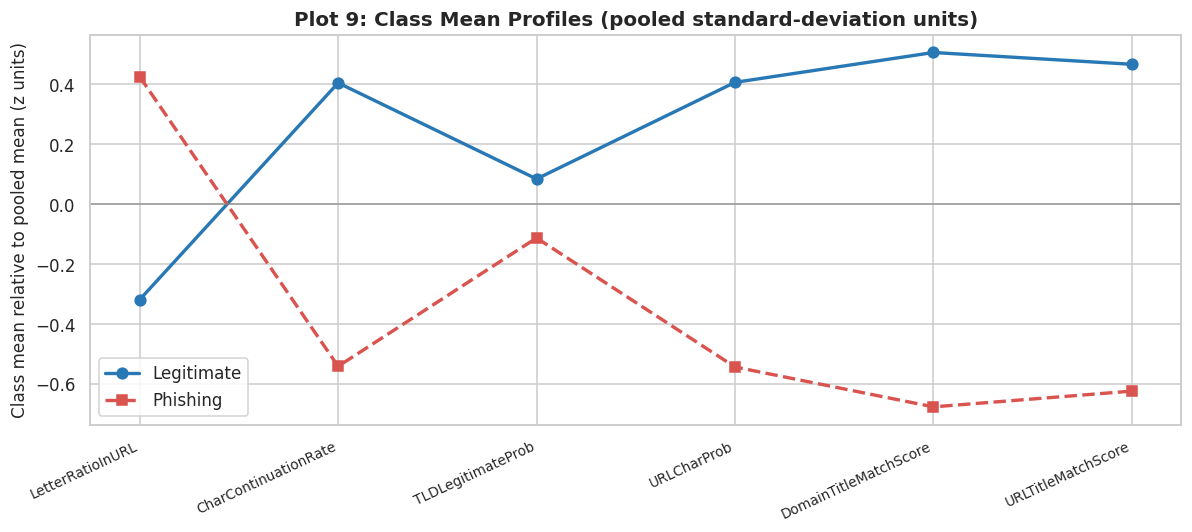

In [18]:
# Compare class means on a common pooled-standard-deviation scale.
# This preserves direction/magnitude instead of independently min-max scaling each class row.
feats_c = ['LetterRatioInURL','CharContinuationRate','TLDLegitimateProb',
           'URLCharProb','DomainTitleMatchScore','URLTitleMatchScore']
pooled_mean = df[feats_c].mean()
pooled_std = df[feats_c].std(ddof=0).replace(0, np.nan)
class_means = df.groupby('label')[feats_c].mean()
class_z = (class_means - pooled_mean) / pooled_std
class_z.index = [LABEL_NAMES[int(i)] for i in class_z.index]
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(feats_c))
ax.plot(x, class_z.loc['Legitimate'], 'o-', color=COLOR_LEGIT, lw=2.2, ms=7, label='Legitimate')
ax.plot(x, class_z.loc['Phishing'], 's--', color=COLOR_PHISH, lw=2.2, ms=7, label='Phishing')
ax.axhline(0, color='gray', linewidth=1, alpha=0.7)
ax.set_xticks(x); ax.set_xticklabels(feats_c, rotation=25, ha='right', fontsize=9)
ax.set_title('Plot 9: Class Mean Profiles (pooled standard-deviation units)', fontweight='bold')
ax.set_ylabel('Class mean relative to pooled mean (z units)'); ax.legend()
plt.tight_layout(); plt.savefig('plot_09.png', bbox_inches='tight'); plt.show()


**Interpretation:** Features are standardized using each feature's pooled mean and standard deviation, so the vertical axis has the same meaning across features. The strongest class differences in this group are in the domain/title match scores and character continuation rate. These are descriptive mean contrasts; skewed distributions and overlapping individual records still matter.

### Plot 10 — Misleading Visualization: Truncated Y-Axis

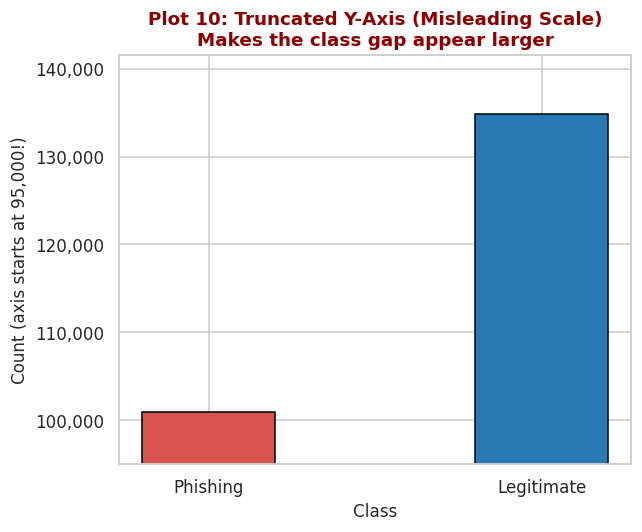

In [19]:
counts = df['label'].value_counts().sort_index()
labels_txt = [LABEL_NAMES[i] for i in counts.index]
colors = [PALETTE[i] for i in counts.index]

fig, ax = plt.subplots(figsize=(6, 5))
ax.bar(labels_txt, counts.values, color=colors, width=0.4, edgecolor='black')
ax.set_ylim(95000, counts.max()*1.05)  # DELIBERATELY MISLEADING
ax.set_title('Plot 10: Truncated Y-Axis (Misleading Scale)\nMakes the class gap appear larger',
             fontsize=12, fontweight='bold', color='darkred')
ax.set_xlabel('Class')
ax.set_ylabel('Count (axis starts at 95,000!)')
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x,_: f'{int(x):,}'))
plt.tight_layout(); plt.savefig('plot_10.png', dpi=110, bbox_inches='tight')
plt.show()


**Interpretation — why this chart misleads:** The displayed Y-axis begins at 95,000 instead of zero. The legitimate bar extends 39,850 units above the cut, while the phishing bar extends 5,945 units; that makes the visible bar heights differ by about **6.7×**. The true counts differ by only **1.34×** (134,850 / 100,945). The altered baseline exaggerates the visual gap.

### Plot 11 — Ethical Redesign: Full Y-Axis

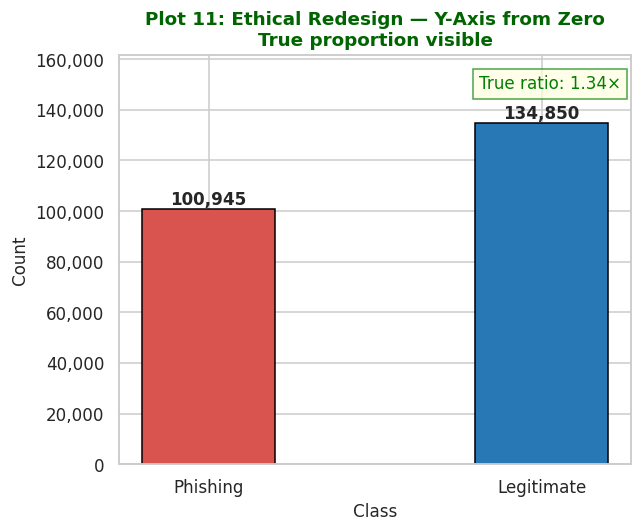

In [20]:
counts = df['label'].value_counts().sort_index()
labels_txt = [LABEL_NAMES[i] for i in counts.index]
colors = [PALETTE[i] for i in counts.index]

fig, ax = plt.subplots(figsize=(6, 5))
bars = ax.bar(labels_txt, counts.values, color=colors, width=0.4, edgecolor='black')
ax.set_ylim(0, counts.max()*1.20)
for bar, cnt in zip(bars, counts.values):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1500,
            f'{cnt:,}', ha='center', fontsize=11, fontweight='bold')
ratio = counts.max()/counts.min()
ax.text(0.98, 0.95, f'True ratio: {ratio:.2f}×',
        transform=ax.transAxes, ha='right', va='top', fontsize=11, color='green',
        bbox=dict(facecolor='lightyellow', edgecolor='green', alpha=0.7))
ax.set_title('Plot 11: Ethical Redesign — Y-Axis from Zero\nTrue proportion visible',
             fontsize=12, fontweight='bold', color='darkgreen')
ax.set_xlabel('Class'); ax.set_ylabel('Count')
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x,_: f'{int(x):,}'))
plt.tight_layout(); plt.savefig('plot_11.png', dpi=110, bbox_inches='tight')
plt.show()


**Interpretation:**
With Y-axis starting at 0, the true 1.34× ratio is visible — not the exaggerated gap the previous chart implied. The ratio annotation makes the proportion explicit. **Key lesson:** Always start bar chart Y-axes at zero unless there is a clear scientific reason, labelled explicitly.


## 4. Seaborn Statistical Visualizations
### Plot 12 — Box Plot: URLLength by Class

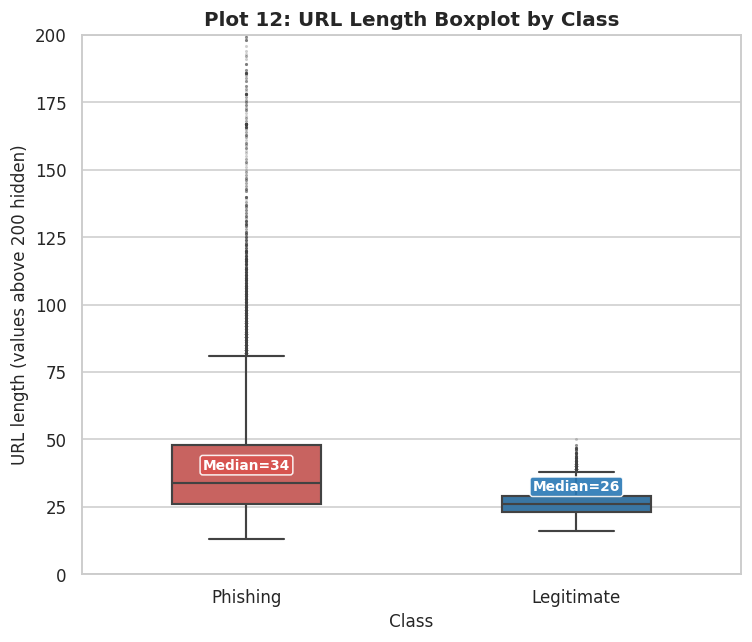

In [21]:
sample = df.sample(n=min(40000, len(df)), random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(7, 6))
sns.boxplot(data=sample, x='label', y='URLLength', palette=[COLOR_PHISH, COLOR_LEGIT], ax=ax,
            showfliers=True, flierprops=dict(marker='.', alpha=0.25, ms=2),
            width=0.45, linewidth=1.4, order=[0,1])
ax.set_xticks([0,1]); ax.set_xticklabels([LABEL_NAMES[0], LABEL_NAMES[1]])
ax.set_ylim(0, 200)
ax.set_title('Plot 12: URL Length Boxplot by Class', fontweight='bold')
ax.set_xlabel('Class'); ax.set_ylabel('URL length (values above 200 hidden)')
for lbl in [0, 1]:
    med = df.loc[df['label']==lbl,'URLLength'].median()
    ax.text(lbl, min(med+5, 190), f'Median={med:.0f}', ha='center', fontsize=9,
            color='white', fontweight='bold', bbox=dict(facecolor=PALETTE[lbl], alpha=0.9, boxstyle='round,pad=0.2'))
plt.tight_layout(); plt.savefig('plot_12.png', bbox_inches='tight'); plt.show()


**Interpretation:** The boxplot summarizes the median, interquartile range and sampled outliers. Full-data medians are 34 characters for phishing and 26 for legitimate URLs. Both distributions have long right tails, and the boxes overlap, so URL length alone cannot identify every record. The chart hides values above 200 to keep the central region legible.

### Plot 13 — Box Plot: LineOfCode (log scale)

/tmp/ipykernel_1214/3676370941.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([LABEL_NAMES[0], LABEL_NAMES[1]])


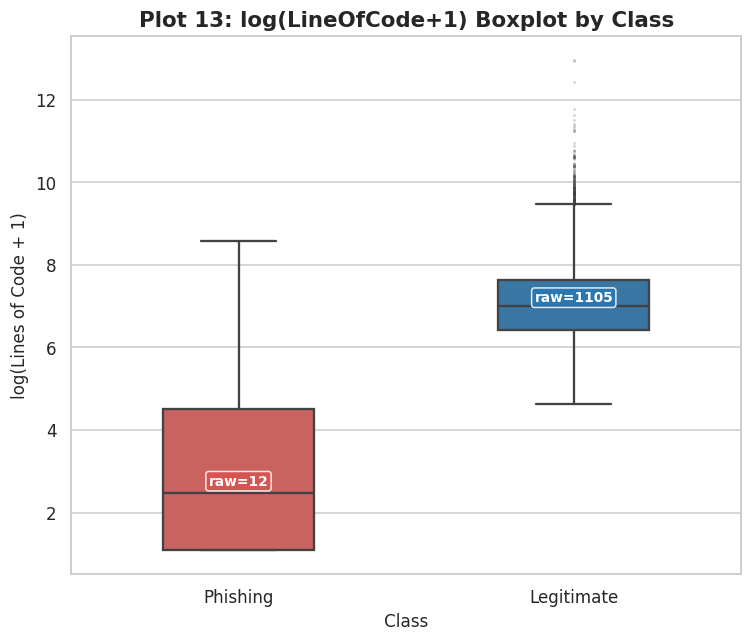

In [22]:
sample = df.sample(40000, random_state=42).copy()
sample['log_LOC'] = np.log1p(sample['LineOfCode'])
fig, ax = plt.subplots(figsize=(7, 6))
sns.boxplot(data=sample, x='label', y='log_LOC', palette=[COLOR_PHISH, COLOR_LEGIT], ax=ax,
            showfliers=True, flierprops=dict(marker='.', alpha=0.2, ms=2),
            width=0.45, linewidth=1.5, order=[0,1])
ax.set_xticklabels([LABEL_NAMES[0], LABEL_NAMES[1]])
ax.set_title('Plot 13: log(LineOfCode+1) Boxplot by Class',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Class'); ax.set_ylabel('log(Lines of Code + 1)')
for lbl in [0,1]:
    raw_med = df.loc[df['label']==lbl,'LineOfCode'].median()
    xi = [0,1].index(lbl)
    ax.text(xi, np.log1p(raw_med)+0.1, f'raw={raw_med:.0f}', ha='center', fontsize=9,
            color='white', fontweight='bold',
            bbox=dict(facecolor=PALETTE[lbl], alpha=0.85, boxstyle='round,pad=0.2'))
plt.tight_layout(); plt.savefig('plot_13.png', dpi=110, bbox_inches='tight')
plt.show()


**Interpretation:** The full-data median is **12 lines of code for phishing** versus **1,105 for legitimate** records. The logarithmic transform makes the central distributions comparable despite extreme right-skew and very large source-code counts. This is a strong descriptive difference, not proof that line count alone separates all records or a validated feature-importance result.

### Plot 14 — Box Plot: NoOfExternalRef (log scale)

/tmp/ipykernel_1214/2585901242.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([LABEL_NAMES[0], LABEL_NAMES[1]])


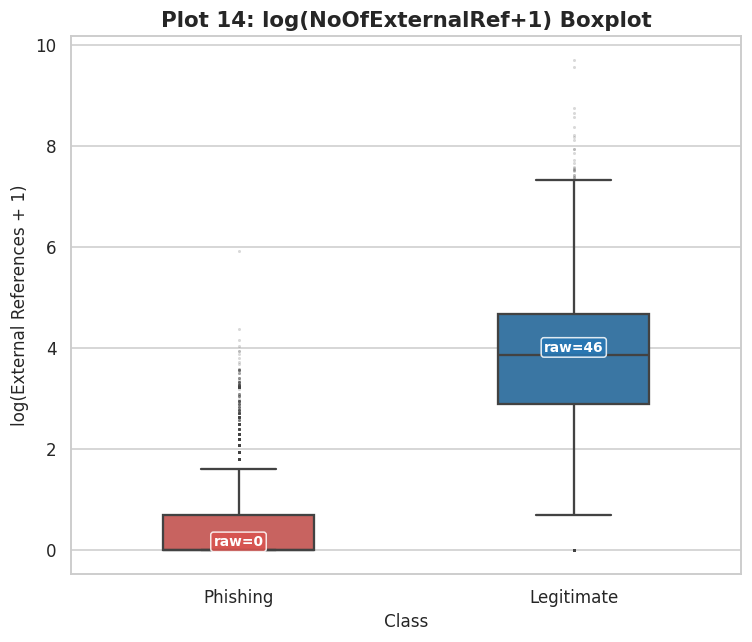

In [23]:
sample = df.sample(40000, random_state=42).copy()
sample['log_ERef'] = np.log1p(sample['NoOfExternalRef'])
fig, ax = plt.subplots(figsize=(7, 6))
sns.boxplot(data=sample, x='label', y='log_ERef', palette=[COLOR_PHISH, COLOR_LEGIT], ax=ax,
            showfliers=True, flierprops=dict(marker='.', alpha=0.2, ms=2),
            width=0.45, linewidth=1.5, order=[0,1])
ax.set_xticklabels([LABEL_NAMES[0], LABEL_NAMES[1]])
ax.set_title('Plot 14: log(NoOfExternalRef+1) Boxplot',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Class'); ax.set_ylabel('log(External References + 1)')
for lbl in [0,1]:
    raw_med = df.loc[df['label']==lbl,'NoOfExternalRef'].median()
    xi = [0,1].index(lbl)
    ax.text(xi, np.log1p(raw_med)+0.08, f'raw={raw_med:.0f}', ha='center', fontsize=9,
            color='white', fontweight='bold',
            bbox=dict(facecolor=PALETTE[lbl], alpha=0.85, boxstyle='round,pad=0.2'))
plt.tight_layout(); plt.savefig('plot_14.png', dpi=110, bbox_inches='tight')
plt.show()


**Interpretation:** The median external-reference count is **0 for phishing** and **46 for legitimate** records. This feature shows a strong distributional difference in this dataset, but the plot does not establish the reason for that difference or prove that external references are safe/unsafe. The logarithmic transform is used only to make the range readable.

### Plot 15 — Violin Plot: URLLength by Class

/tmp/ipykernel_1214/4225650851.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([LABEL_NAMES[0], LABEL_NAMES[1]])


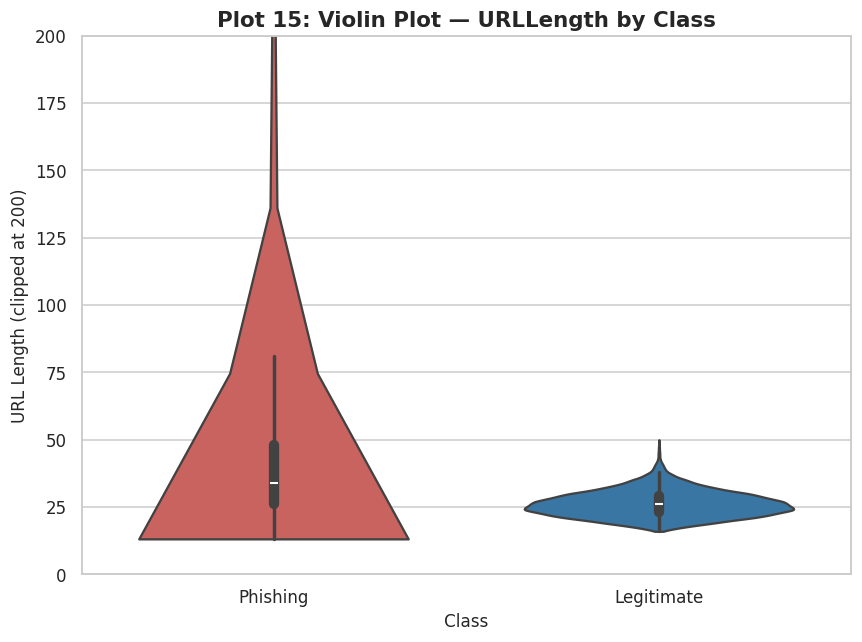

In [24]:
sample = df.sample(40000, random_state=42)
fig, ax = plt.subplots(figsize=(8, 6))
sns.violinplot(data=sample, x='label', y='URLLength', palette=[COLOR_PHISH, COLOR_LEGIT],
               ax=ax, inner='box', cut=0, width=0.7, linewidth=1.5, order=[0,1])
ax.set_xticklabels([LABEL_NAMES[0], LABEL_NAMES[1]])
ax.set_ylim(0, 200)
ax.set_title('Plot 15: Violin Plot — URLLength by Class',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Class'); ax.set_ylabel('URL Length (clipped at 200)')
plt.tight_layout(); plt.savefig('plot_15.png', dpi=110, bbox_inches='tight')
plt.show()


**Interpretation:** The violin plot combines a kernel-density shape with an inner boxplot for the sampled data. It complements the boxplot by showing where values concentrate, while the restricted vertical view omits URL lengths above 200. KDE shapes are smoothed estimates, so they should be read as distribution summaries rather than exact frequencies.

### Plot 16 — KDE Plot: CharContinuationRate by Class

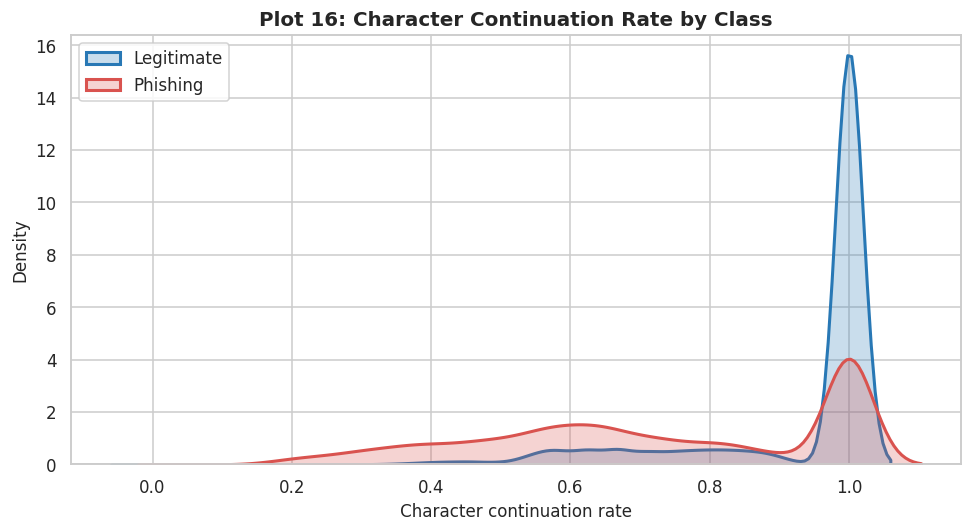

In [25]:
fig, ax = plt.subplots(figsize=(9, 5))
for lbl, color in PALETTE.items():
    data = df.loc[df['label']==lbl, 'CharContinuationRate'].sample(
        n=min(18000, int((df['label']==lbl).sum())), random_state=RANDOM_STATE)
    sns.kdeplot(data=data, ax=ax, color=color, fill=True, alpha=0.25, linewidth=2,
                label=LABEL_NAMES[lbl], bw_adjust=1.0)
ax.set_title('Plot 16: Character Continuation Rate by Class', fontweight='bold')
ax.set_xlabel('Character continuation rate'); ax.set_ylabel('Density'); ax.legend()
plt.tight_layout(); plt.savefig('plot_16.png', bbox_inches='tight'); plt.show()


**Interpretation:** The class distributions for `CharContinuationRate` differ, with the full-data median at 1.000 for legitimate records and about 0.727 for phishing records. The KDE is estimated from reproducible samples; overlap remains, and the pattern is an association in this dataset rather than a universal rule about URL character sequences.

### Plot 17 — Correlation Heatmap (Numerical Features)

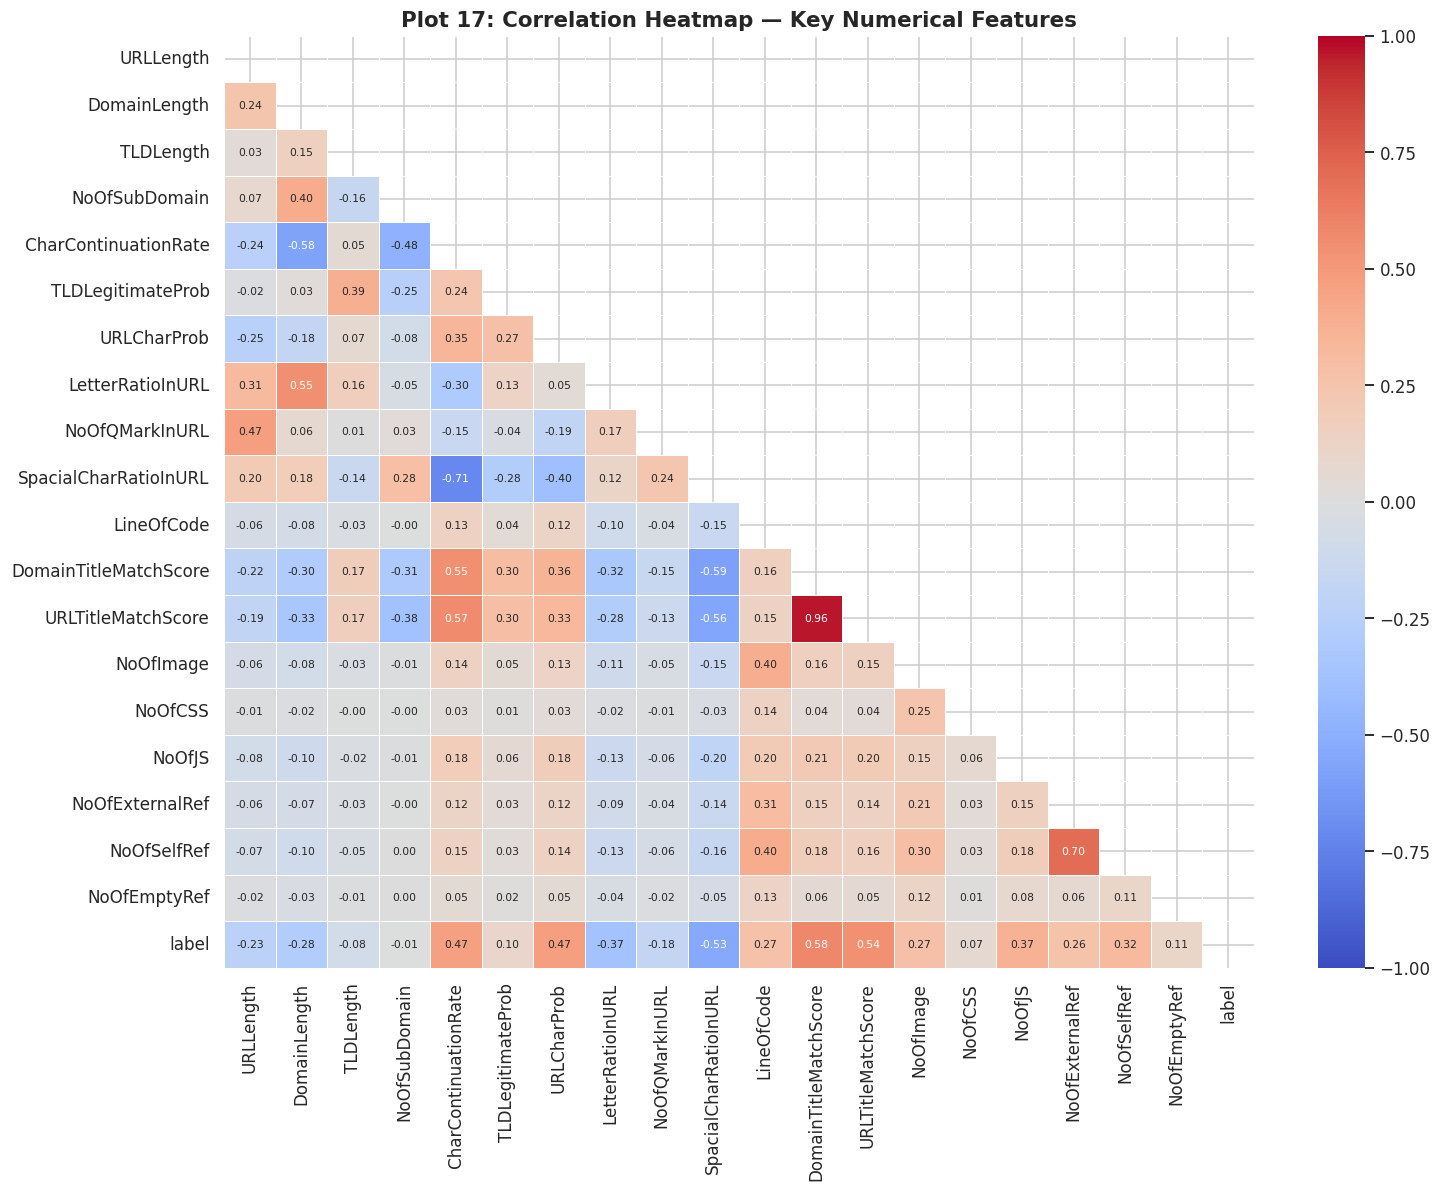

In [26]:
heat_cols = ['URLLength','DomainLength','TLDLength','NoOfSubDomain',
             'CharContinuationRate','TLDLegitimateProb','URLCharProb',
             'LetterRatioInURL','NoOfQMarkInURL','SpacialCharRatioInURL',
             'LineOfCode','DomainTitleMatchScore','URLTitleMatchScore',
             'NoOfImage','NoOfCSS','NoOfJS','NoOfExternalRef',
             'NoOfSelfRef','NoOfEmptyRef','label']
corr = df[heat_cols].corr()

fig, ax = plt.subplots(figsize=(14, 11))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, vmin=-1, vmax=1, linewidths=0.4, ax=ax,
            annot_kws={'size': 7})
ax.set_title('Plot 17: Correlation Heatmap — Key Numerical Features',
             fontsize=14, fontweight='bold')
plt.tight_layout(); plt.savefig('plot_17.png', dpi=110, bbox_inches='tight')
plt.show()


**Interpretation:** The correlation matrix reports pairwise linear associations among the selected numeric features. `LineOfCode`, `NoOfImage`, `NoOfCSS`, `NoOfJS` and reference-count features tend to capture related aspects of page complexity. The target is coded 1 for legitimate, so positive correlations with `label` indicate an association with legitimate records, while negative correlations indicate an association with phishing records. Correlation is not causation, and the heatmap alone is not a feature-selection or model-validation procedure.

### Plot 18 — Categorical Strip Plot: NoOfSubDomain by Class

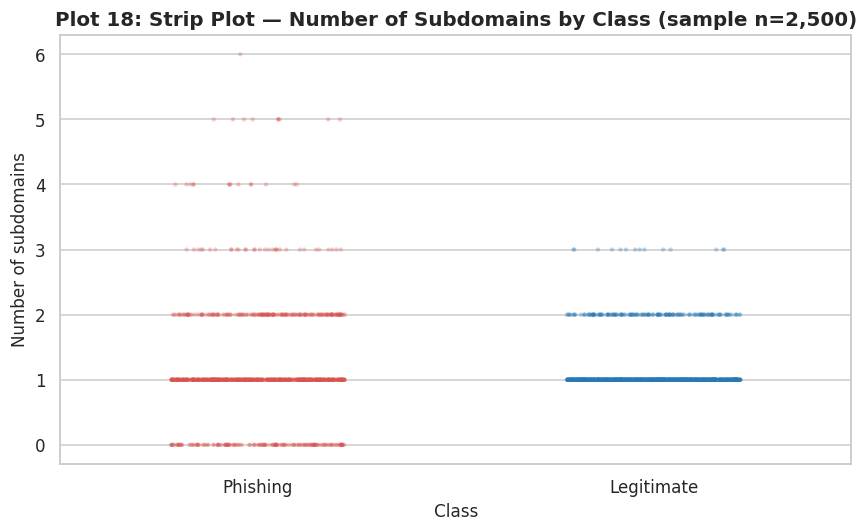

In [27]:
# Plot 18: jittered categorical strip plot; swarm packing is unusually slow for this highly discrete feature.
sample_swarm = df.sample(n=min(2500, len(df)), random_state=RANDOM_STATE).copy()
fig, ax = plt.subplots(figsize=(8, 5))
sns.stripplot(data=sample_swarm, x='label', y='NoOfSubDomain', order=[0,1],
              hue='label', hue_order=[0,1], palette=PALETTE, dodge=False,
              jitter=0.22, alpha=0.30, size=2.8, ax=ax, legend=False)
ax.set_xticks([0,1]); ax.set_xticklabels([LABEL_NAMES[0], LABEL_NAMES[1]])
ax.set_title('Plot 18: Strip Plot — Number of Subdomains by Class (sample n=2,500)', fontweight='bold')
ax.set_xlabel('Class'); ax.set_ylabel('Number of subdomains')
plt.tight_layout(); plt.savefig('plot_18.png', bbox_inches='tight'); plt.show()


**Interpretation:** The swarm plot displays a deterministic sample of 900 records so the discrete subdomain counts remain visible. Both classes frequently have one subdomain, so this attribute alone provides limited visual separation. This is a sample-based visual check, not a feature-importance estimate.

### Plot 19 — Pair Plot: Key Features Coloured by Class

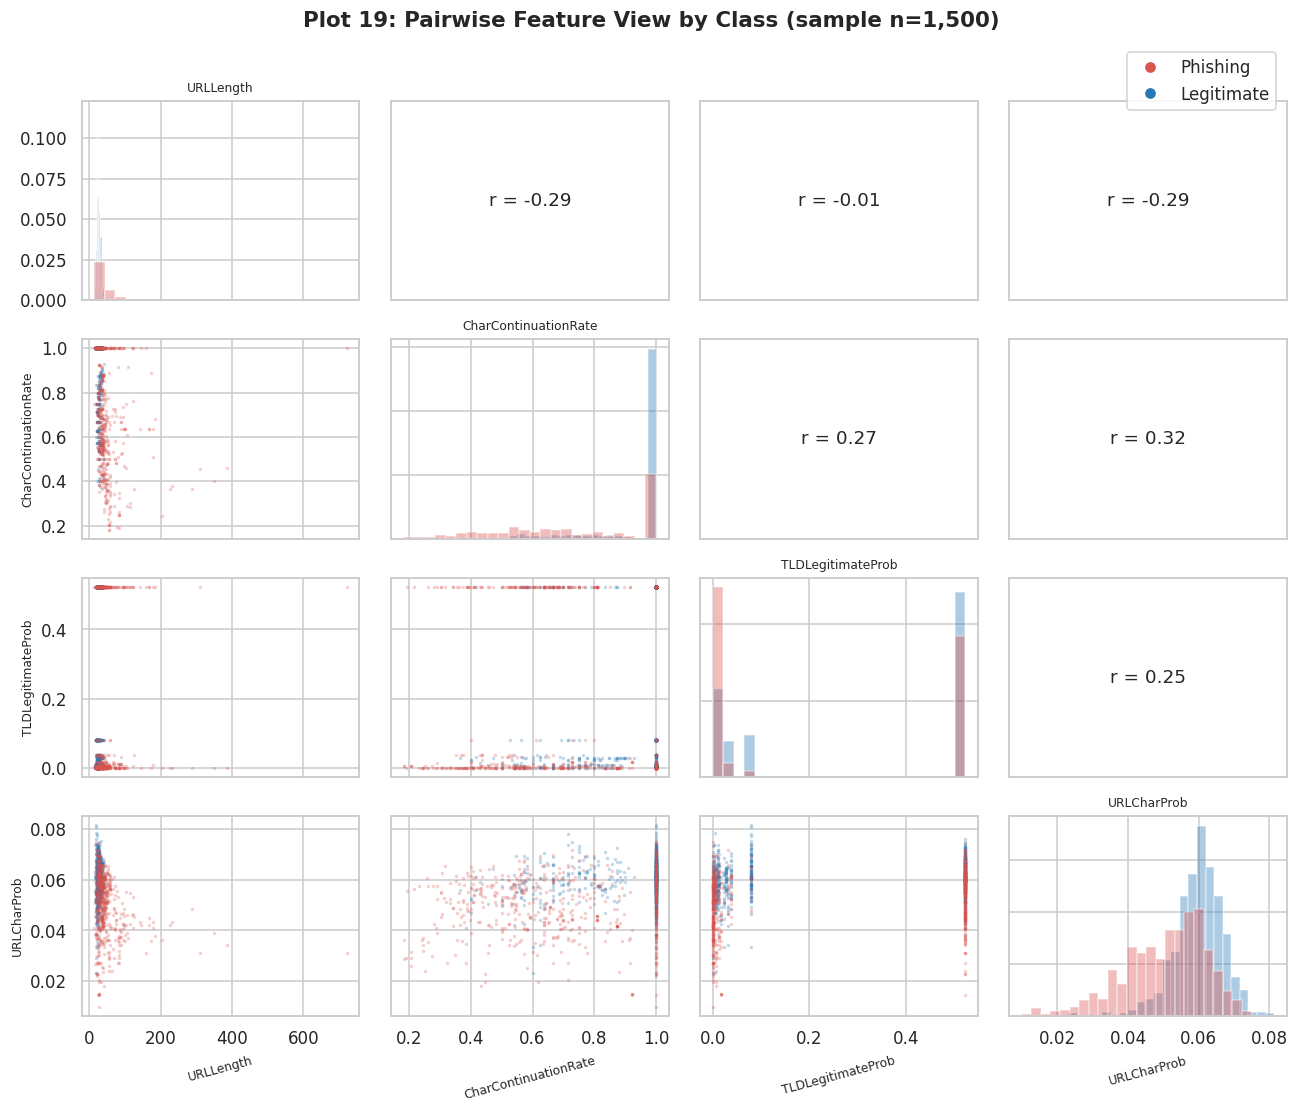

In [28]:
# Plot 19: Pairwise feature view — manual grid keeps execution fast and the sample explicit.
pair_feats = ['URLLength','CharContinuationRate','TLDLegitimateProb','URLCharProb']
sample_pair = df.sample(n=min(1500, len(df)), random_state=RANDOM_STATE).copy()
sample_pair['Class'] = sample_pair['label'].map(LABEL_NAMES)
fig, axes = plt.subplots(len(pair_feats), len(pair_feats), figsize=(12, 10))
for i, yfeat in enumerate(pair_feats):
    for j, xfeat in enumerate(pair_feats):
        ax = axes[i, j]
        if i == j:
            for cls, color in [('Legitimate', COLOR_LEGIT), ('Phishing', COLOR_PHISH)]:
                vals = sample_pair.loc[sample_pair['Class']==cls, xfeat]
                ax.hist(vals, bins=24, density=True, alpha=0.38, color=color, label=cls)
        elif i > j:
            for cls, color in [('Legitimate', COLOR_LEGIT), ('Phishing', COLOR_PHISH)]:
                sub = sample_pair[sample_pair['Class']==cls]
                ax.scatter(sub[xfeat], sub[yfeat], s=5, alpha=0.28, color=color, label=cls, linewidths=0)
        else:
            corr_val = sample_pair[[xfeat, yfeat]].corr().iloc[0,1]
            ax.text(0.5, 0.5, f'r = {corr_val:.2f}', ha='center', va='center', fontsize=12, transform=ax.transAxes)
            ax.set_xticks([]); ax.set_yticks([])
        if i == len(pair_feats)-1: ax.set_xlabel(xfeat, fontsize=8, rotation=15)
        else: ax.set_xticklabels([])
        if j == 0 and i != j: ax.set_ylabel(yfeat, fontsize=8)
        elif j != 0: ax.set_yticklabels([])
        if i == j: ax.set_title(xfeat, fontsize=8)
fig.suptitle('Plot 19: Pairwise Feature View by Class (sample n=1,500)', fontsize=14, fontweight='bold', y=1.01)
handles = [plt.Line2D([0],[0], marker='o', linestyle='', color=COLOR_PHISH, label='Phishing'),
           plt.Line2D([0],[0], marker='o', linestyle='', color=COLOR_LEGIT, label='Legitimate')]
fig.legend(handles=handles, loc='upper right', bbox_to_anchor=(0.98,0.98))
plt.tight_layout(); plt.savefig('plot_19.png', bbox_inches='tight'); plt.show()


**Interpretation:** The pair plot reveals univariate distributions on the diagonal and pairwise relationships in the off-diagonal panels. `CharContinuationRate` and `TLDLegitimateProb` differ in distribution across classes, while overlap remains. The plot is exploratory; two-dimensional separation is not equivalent to validated predictive performance.

### Plot 20 — Count Plot: Binary Features Presence by Class

/tmp/ipykernel_1214/1473898842.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha='right')


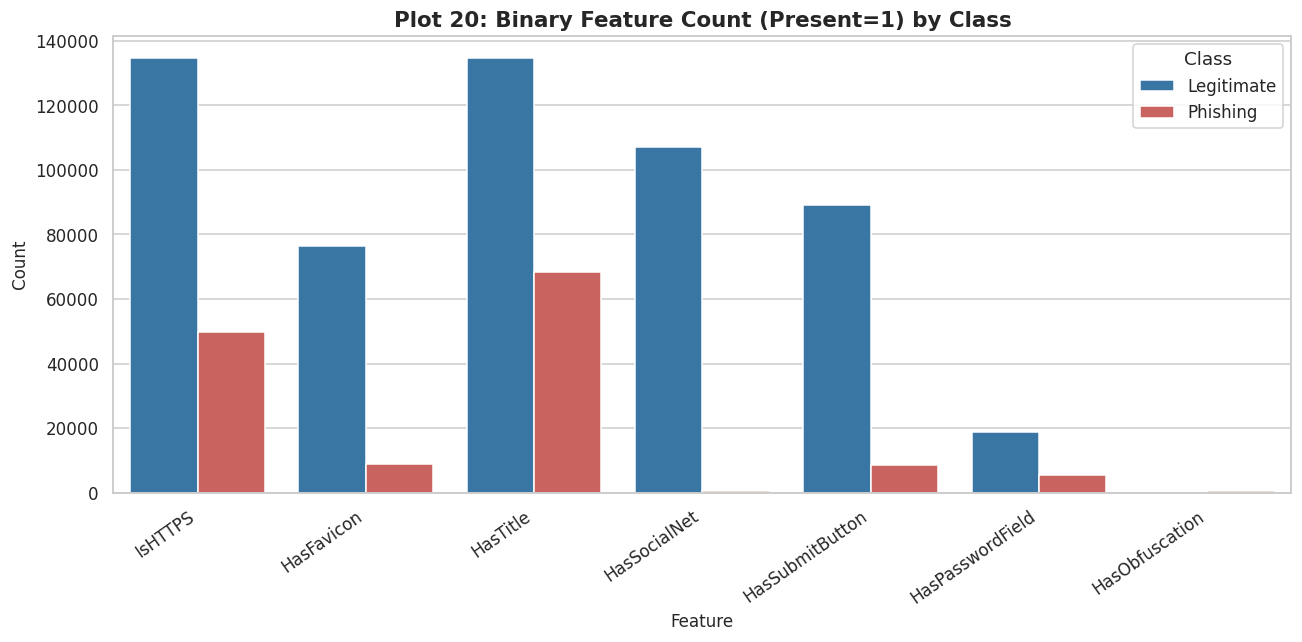

In [29]:
bin_feats = ['IsHTTPS','HasFavicon','HasTitle','HasSocialNet',
             'HasSubmitButton','HasPasswordField','HasObfuscation']
melted = df[bin_feats + ['label']].melt(id_vars='label',
            var_name='Feature', value_name='Present')
melted_yes = melted[melted['Present']==1].copy()
melted_yes['Class'] = melted_yes['label'].map(LABEL_NAMES)

fig, ax = plt.subplots(figsize=(12, 6))
sns.countplot(data=melted_yes, x='Feature', hue='Class',
              palette={'Legitimate': COLOR_LEGIT, 'Phishing': COLOR_PHISH}, ax=ax)
ax.set_title('Plot 20: Binary Feature Count (Present=1) by Class',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Feature'); ax.set_ylabel('Count')
ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha='right')
ax.legend(title='Class')
plt.tight_layout(); plt.savefig('plot_20.png', dpi=110, bbox_inches='tight')
plt.show()


**Interpretation:** The plot compares raw counts of records where each binary flag equals 1; raw counts are affected by the larger legitimate class. The rate heatmap in Plot 24 is better for comparing prevalence. On the full dataset, `IsHTTPS` is present in 100.0% of legitimate records but 49.2% of phishing records, and `HasTitle` is present in 99.9% versus 67.8%. HTTPS alone is not a sufficient safety guarantee.

## 5. Advanced Static Visualizations
### Plot 21 — Outlier Detection (IQR Method)

Q1=23.0, Q3=34.0, IQR=11.0
Fences: [6, 50]
Outliers: 22,493 (9.5%) | Phishing in outliers: 99.9%


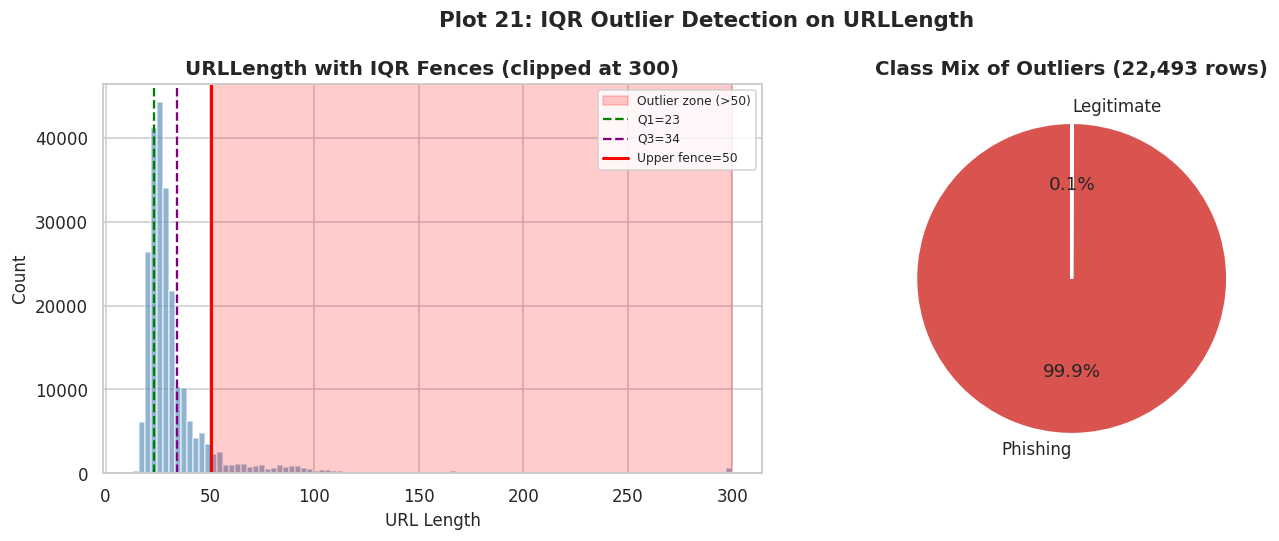

In [30]:
feature = 'URLLength'
Q1 = df[feature].quantile(0.25); Q3 = df[feature].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5*IQR; upper = Q3 + 1.5*IQR
outliers = df[(df[feature]<lower)|(df[feature]>upper)]
n_out = len(outliers)
print(f'Q1={Q1}, Q3={Q3}, IQR={IQR}')
print(f'Fences: [{lower:.0f}, {upper:.0f}]')
print(f'Outliers: {n_out:,} ({n_out/len(df)*100:.1f}%) '
      f'| Phishing in outliers: {outliers["label"].eq(0).mean()*100:.1f}%')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
ax.hist(df[feature].clip(upper=300), bins=100, color='steelblue', alpha=0.6)
ax.axvspan(upper, 300, color='red', alpha=0.2, label=f'Outlier zone (>{upper:.0f})')
ax.axvline(Q1, color='green', ls='--', lw=1.5, label=f'Q1={Q1:.0f}')
ax.axvline(Q3, color='purple', ls='--', lw=1.5, label=f'Q3={Q3:.0f}')
ax.axvline(upper, color='red', ls='-', lw=2, label=f'Upper fence={upper:.0f}')
ax.set_title('URLLength with IQR Fences (clipped at 300)', fontweight='bold')
ax.set_xlabel('URL Length'); ax.set_ylabel('Count')
ax.legend(fontsize=8)

ax2 = axes[1]
out_comp = outliers['label'].value_counts()
ax2.pie(out_comp.values,
        labels=[LABEL_NAMES[k] for k in out_comp.index],
        colors=[PALETTE[k] for k in out_comp.index],
        autopct='%1.1f%%', startangle=90,
        wedgeprops=dict(edgecolor='white', lw=2))
ax2.set_title(f'Class Mix of Outliers ({n_out:,} rows)', fontweight='bold')
plt.suptitle('Plot 21: IQR Outlier Detection on URLLength',
             fontsize=14, fontweight='bold')
plt.tight_layout(); plt.savefig('plot_21.png', dpi=110, bbox_inches='tight')
plt.show()


**Interpretation:** The IQR method flags URL lengths outside the standard 1.5×IQR fences. These points are statistical outliers, not necessarily data errors. The class mix describes this dataset only; unusually long URLs should not be removed automatically because they may represent relevant behavior. Inspect their validity and role before any modeling or cleaning decision.

### Plot 22 — URL Length Binning Analysis

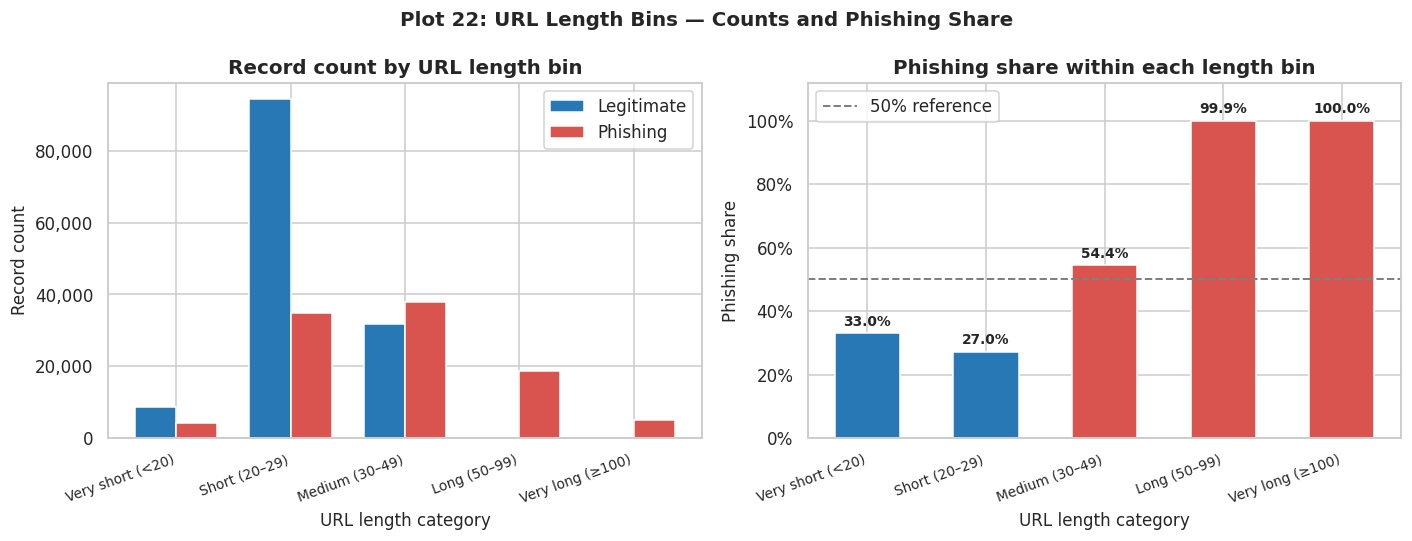

In [31]:
bin_counts = df.groupby(['URLLength_bin','label'], observed=False).size().unstack(fill_value=0)
bin_counts = bin_counts.reindex(length_labels, fill_value=0)
bin_counts.columns = [LABEL_NAMES[int(c)] for c in bin_counts.columns]
bin_counts['Total'] = bin_counts.sum(axis=1)
bin_counts['PhishRate'] = np.where(bin_counts['Total'] > 0,
                                    bin_counts.get('Phishing', 0) / bin_counts['Total'], np.nan)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
x = np.arange(len(bin_counts)); w = 0.36
ax = axes[0]
ax.bar(x-w/2, bin_counts['Legitimate'], width=w, color=COLOR_LEGIT, label='Legitimate', edgecolor='white')
ax.bar(x+w/2, bin_counts['Phishing'], width=w, color=COLOR_PHISH, label='Phishing', edgecolor='white')
ax.set_xticks(x); ax.set_xticklabels(bin_counts.index, rotation=20, ha='right', fontsize=9)
ax.set_title('Record count by URL length bin', fontweight='bold'); ax.set_xlabel('URL length category'); ax.set_ylabel('Record count')
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x,_: f'{int(x):,}')); ax.legend()
ax2 = axes[1]
rates = bin_counts['PhishRate'].fillna(0)
bar_colors = [COLOR_PHISH if r >= 0.5 else COLOR_LEGIT for r in rates]
bars2 = ax2.bar(x, rates, color=bar_colors, width=0.55, edgecolor='white')
ax2.axhline(0.5, color='gray', ls='--', lw=1.3, label='50% reference')
ax2.set_xticks(x); ax2.set_xticklabels(bin_counts.index, rotation=20, ha='right', fontsize=9)
ax2.set_title('Phishing share within each length bin', fontweight='bold'); ax2.set_xlabel('URL length category'); ax2.set_ylabel('Phishing share')
ax2.set_ylim(0, 1.12); ax2.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1)); ax2.legend()
for bar, rate in zip(bars2, rates):
    ax2.text(bar.get_x()+bar.get_width()/2, rate+0.025, f'{rate*100:.1f}%', ha='center', fontsize=9, fontweight='bold')
plt.suptitle('Plot 22: URL Length Bins — Counts and Phishing Share', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.savefig('plot_22.png', bbox_inches='tight'); plt.show()


**Interpretation:** With the documented label mapping and bins `[0,20)`, `[20,30)`, `[30,50)`, `[50,100)` and `≥100`, the phishing share is approximately **33.0%, 27.0%, 54.4%, 99.9% and 100.0%**, respectively. The last two categories are highly phishing-heavy in this dataset. Treat these as sample-level associations, not a universal rule; inspect bin counts alongside percentages before making decisions.

### Plot 23 — Error Bar Chart: Mean ± 95% CI

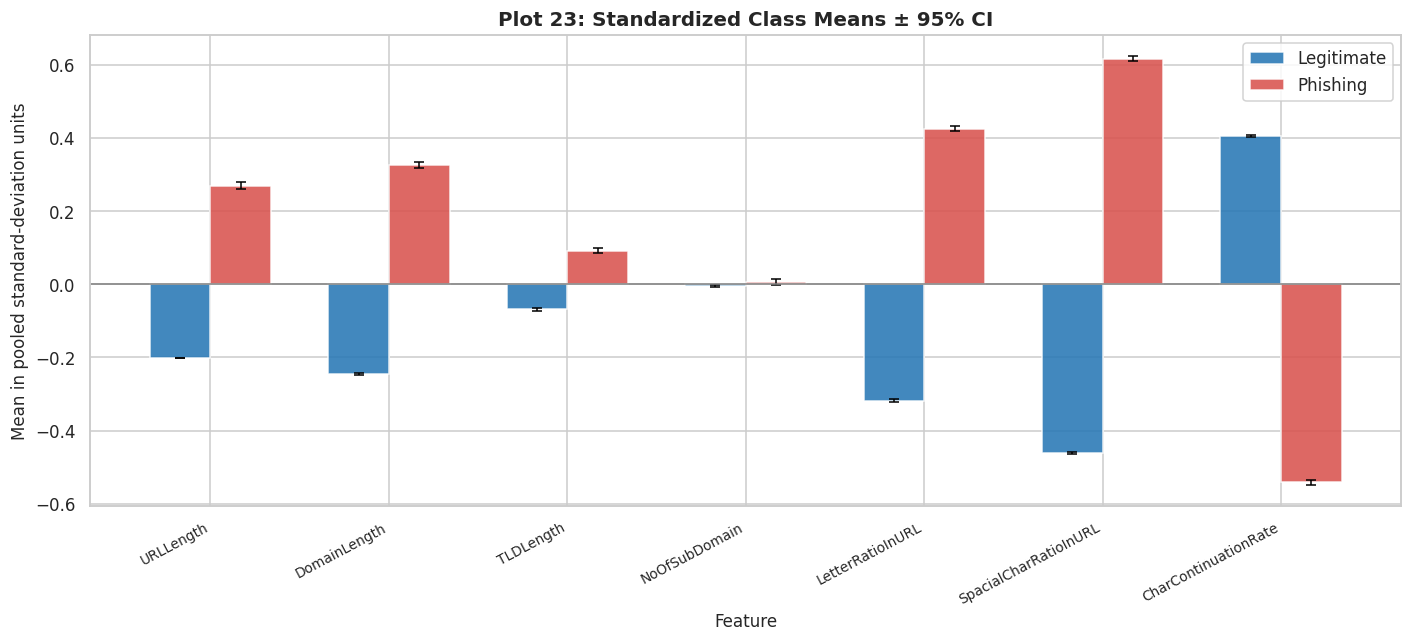

In [32]:
feats_eb = ['URLLength','DomainLength','TLDLength','NoOfSubDomain',
            'LetterRatioInURL','SpacialCharRatioInURL','CharContinuationRate']
results = []
for feat in feats_eb:
    pooled_mean = df[feat].mean()
    pooled_sd = df[feat].std(ddof=0)
    for lbl in [0,1]:
        data = df.loc[df['label']==lbl, feat].dropna()
        zdata = (data - pooled_mean) / pooled_sd if pooled_sd else data*0
        mean = zdata.mean()
        sem = scipy_stats.sem(zdata)
        ci = sem * scipy_stats.t.ppf(0.975, max(len(zdata)-1, 1))
        results.append({'Feature':feat,'Class':LABEL_NAMES[lbl],'MeanZ':mean,'CI95':ci})
eb_df = pd.DataFrame(results)
fig, ax = plt.subplots(figsize=(13, 6))
x = np.arange(len(feats_eb)); w = 0.34
for i, (cls, color) in enumerate([('Legitimate',COLOR_LEGIT),('Phishing',COLOR_PHISH)]):
    sub = eb_df[eb_df['Class']==cls].set_index('Feature').loc[feats_eb]
    xpos = x + (i-0.5)*w
    ax.bar(xpos, sub['MeanZ'], width=w, color=color, label=cls, alpha=0.88)
    ax.errorbar(xpos, sub['MeanZ'], yerr=sub['CI95'], fmt='none', color='black', capsize=3, lw=1)
ax.axhline(0, color='gray', linewidth=1)
ax.set_xticks(x); ax.set_xticklabels(feats_eb, rotation=28, ha='right', fontsize=9)
ax.set_title('Plot 23: Standardized Class Means ± 95% CI', fontweight='bold')
ax.set_xlabel('Feature'); ax.set_ylabel('Mean in pooled standard-deviation units'); ax.legend()
plt.tight_layout(); plt.savefig('plot_23.png', bbox_inches='tight'); plt.show()


**Interpretation:** Each feature is standardized using its overall mean and standard deviation, so unlike raw units the means are visually comparable across features. The confidence intervals are narrow because the dataset is large; that does not establish practical importance or causal effect. Feature distributions are skewed, so interpret the standardized mean chart alongside medians and distribution plots.

### Plot 24 — Custom Colormap Heatmap: Binary Feature Rates

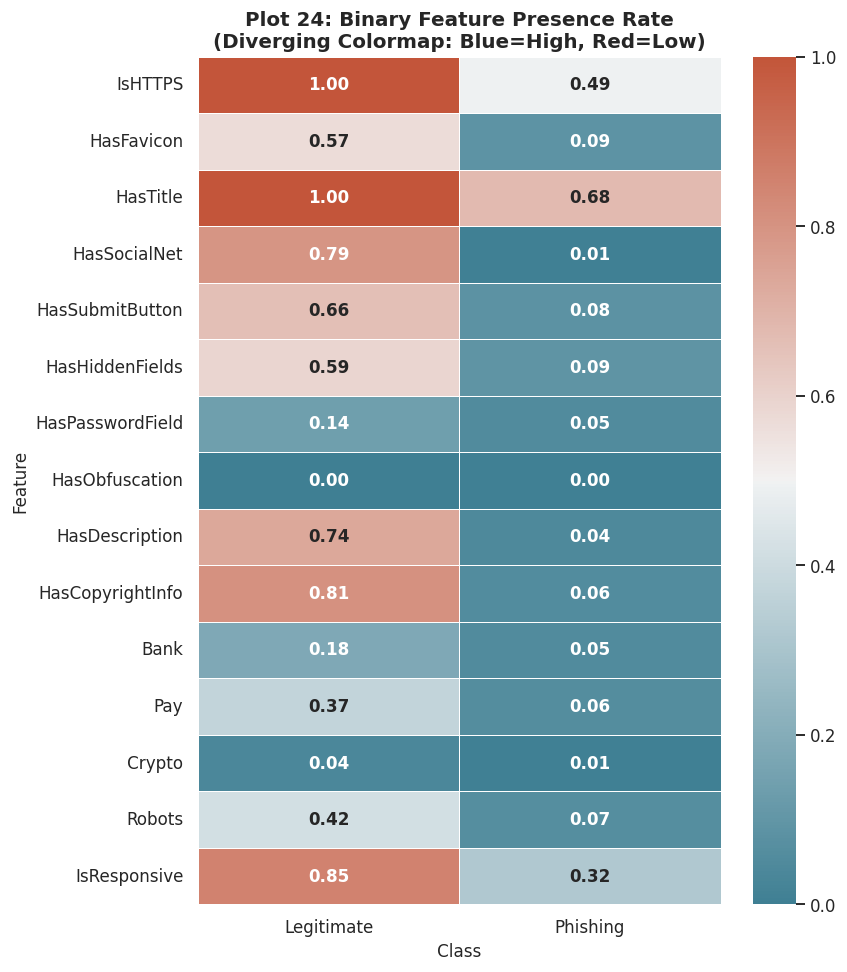

In [33]:
bin_features = ['IsHTTPS','HasFavicon','HasTitle','HasSocialNet',
                'HasSubmitButton','HasHiddenFields','HasPasswordField',
                'HasObfuscation','HasDescription','HasCopyrightInfo',
                'Bank','Pay','Crypto','Robots','IsResponsive']
rates = {f: {'Legitimate': df[df['label']==1][f].mean(),
             'Phishing':   df[df['label']==0][f].mean()}
         for f in bin_features}
rates_df = pd.DataFrame(rates).T

fig, ax = plt.subplots(figsize=(8, 9))
cmap_custom = sns.diverging_palette(220, 20, as_cmap=True)
sns.heatmap(rates_df, annot=True, fmt='.2f', cmap=cmap_custom,
            center=0.5, vmin=0, vmax=1, linewidths=0.5, ax=ax,
            annot_kws={'size': 11, 'weight': 'bold'})
ax.set_title('Plot 24: Binary Feature Presence Rate\n(Diverging Colormap: Blue=High, Red=Low)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Class'); ax.set_ylabel('Feature')
plt.tight_layout(); plt.savefig('plot_24.png', dpi=110, bbox_inches='tight')
plt.show()


**Interpretation:** The heatmap reports the observed proportion of each binary feature among each class (0–1 scale). Notable full-dataset rates include `HasTitle` (99.9% legitimate vs 67.8% phishing), `HasCopyrightInfo` (80.8% vs 5.7%), and `IsHTTPS` (100.0% vs 49.2%). `Crypto` is present in 3.7% of legitimate records and 0.6% of phishing records in this dataset, so it should **not** be described here as more common among phishing records. These are dataset associations and may not generalize to new data.

### Plot 25 — Scatter with Custom Colormap: URLCharProb vs TLDLegitimateProb

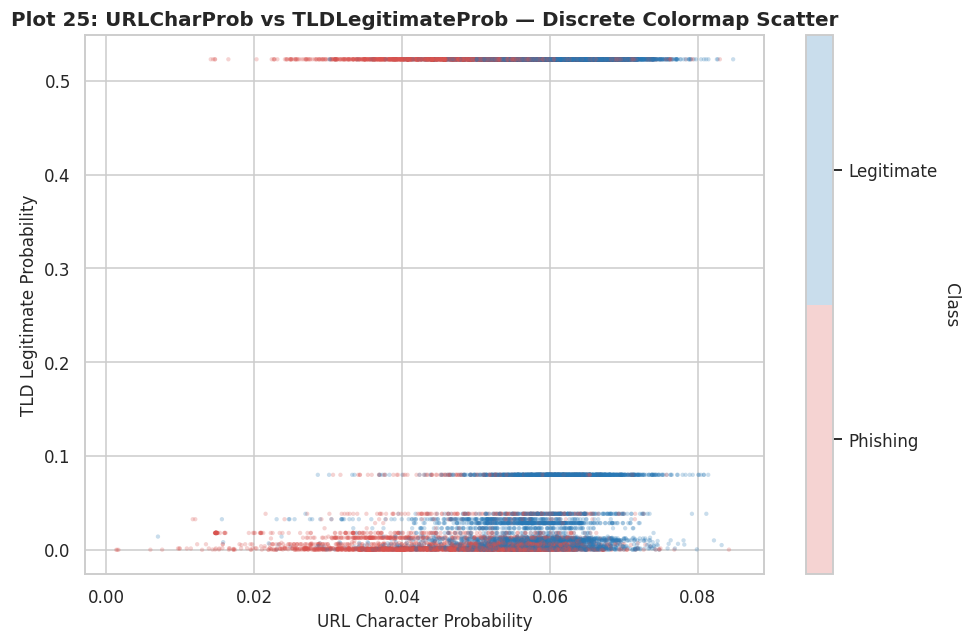

In [34]:
sample = df.sample(15000, random_state=42)
cmap_disc = ListedColormap([COLOR_PHISH, COLOR_LEGIT])
fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(sample['URLCharProb'], sample['TLDLegitimateProb'],
                c=sample['label'], cmap=cmap_disc,
                alpha=0.25, s=8, linewidths=0)
cbar = plt.colorbar(sc, ax=ax, ticks=[0.25, 0.75])
cbar.ax.set_yticklabels(['Phishing', 'Legitimate'])
cbar.set_label('Class', rotation=270, labelpad=15)
ax.set_title('Plot 25: URLCharProb vs TLDLegitimateProb — Discrete Colormap Scatter',
             fontsize=13, fontweight='bold')
ax.set_xlabel('URL Character Probability')
ax.set_ylabel('TLD Legitimate Probability')
plt.tight_layout(); plt.savefig('plot_25.png', dpi=110, bbox_inches='tight')
plt.show()


**Interpretation:** The scatterplot shows two feature values colored by the class label for a reproducible 15,000-row sample. Legitimate records have a higher median `TLDLegitimateProb` (0.523 versus 0.018), but the overlap and the distributions of `URLCharProb` show why a two-feature view is not a complete detection rule. This is exploratory evidence, not a model-performance result.

## 6. 3D Visualizations
### Plot 26 — 3D Scatter Plot

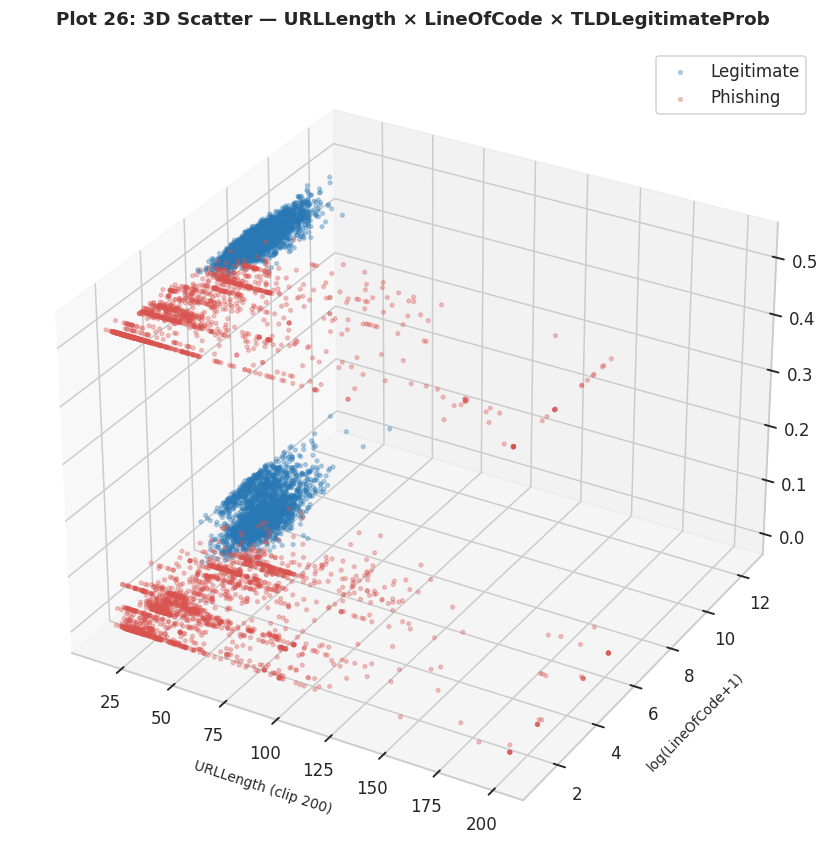

In [35]:
sample3d = df.sample(8000, random_state=42)
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection='3d')
for lbl, color in PALETTE.items():
    sub = sample3d[sample3d['label']==lbl]
    ax.scatter(sub['URLLength'].clip(upper=200),
               np.log1p(sub['LineOfCode']),
               sub['TLDLegitimateProb'],
               c=color, label=LABEL_NAMES[lbl], alpha=0.3, s=6)
ax.set_xlabel('URLLength (clip 200)', fontsize=9, labelpad=8)
ax.set_ylabel('log(LineOfCode+1)', fontsize=9, labelpad=8)
ax.set_zlabel('TLDLegitimateProb', fontsize=9, labelpad=8)
ax.set_title('Plot 26: 3D Scatter — URLLength × LineOfCode × TLDLegitimateProb',
             fontsize=12, fontweight='bold', pad=15)
ax.legend()
plt.tight_layout(); plt.savefig('plot_26.png', dpi=110, bbox_inches='tight')
plt.show()


**Interpretation:** The 3D view combines URL length, log-transformed page line count and TLD legitimacy probability. In the full data, median URL length is 34 characters for phishing versus 26 for legitimate; median `LineOfCode` is 12 versus 1,105; median `TLDLegitimateProb` is 0.018 versus 0.523. The 3D view is exploratory and perspective-dependent; it does not prove that these features alone can classify URLs.

### Plot 27 — 3D Surface Plot: Phishing Rate Grid

Cells with ≥50 records displayed: 10 of 100


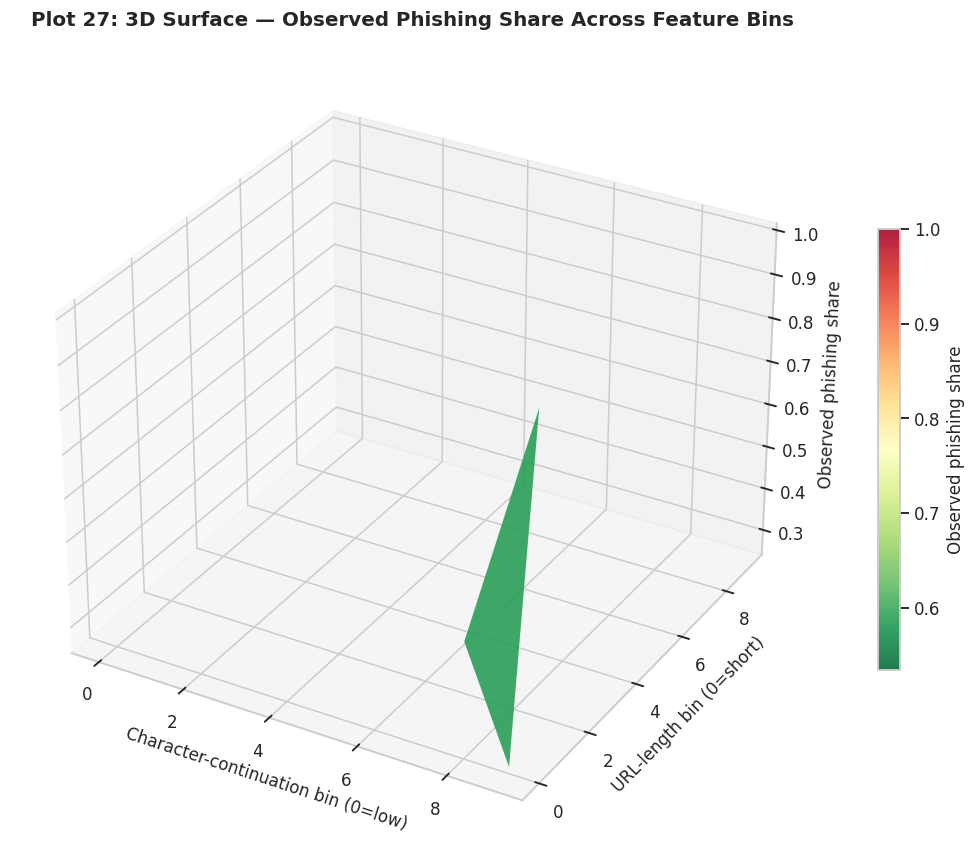

In [36]:
# Aggregate observed phishing share over a 10 x 10 feature grid; hide low-support cells.
df_s = df[['URLLength','CharContinuationRate','label']].copy()
df_s['URLLen_bin'] = pd.cut(df_s['URLLength'], bins=10, labels=False, include_lowest=True)
df_s['CharCC_bin'] = pd.cut(df_s['CharContinuationRate'], bins=10, labels=False, include_lowest=True)
grouped = df_s.groupby(['URLLen_bin','CharCC_bin'], observed=True)['label'].agg(['count','mean'])
rate_table = (1 - grouped['mean']).unstack().reindex(index=range(10), columns=range(10))
count_table = grouped['count'].unstack().reindex(index=range(10), columns=range(10)).fillna(0)
X = np.array(rate_table.columns, dtype=float); Y = np.array(rate_table.index, dtype=float)
Xg, Yg = np.meshgrid(X, Y)
Zraw = rate_table.values.astype(float)
Z = np.where(count_table.values >= 50, Zraw, np.nan)  # suppress cells supported by fewer than 50 records
print('Cells with ≥50 records displayed:', int(np.isfinite(Z).sum()), 'of', Z.size)
fig = plt.figure(figsize=(12, 8)); ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(Xg, Yg, np.ma.masked_invalid(Z), cmap='RdYlGn_r', alpha=0.88, edgecolor='none')
fig.colorbar(surf, ax=ax, label='Observed phishing share', shrink=0.55)
ax.set_xlabel('Character-continuation bin (0=low)'); ax.set_ylabel('URL-length bin (0=short)'); ax.set_zlabel('Observed phishing share')
ax.set_title('Plot 27: 3D Surface — Observed Phishing Share Across Feature Bins', fontweight='bold', pad=15)
plt.tight_layout(); plt.savefig('plot_27.png', bbox_inches='tight'); plt.show()


**Interpretation:** The surface is calculated from the observed fraction of label-0 records in each URL-length × character-continuation bin. Bins with fewer than 50 records are hidden to avoid visually overinterpreting sparse groups. This is an aggregated descriptive rate on the supplied dataset—not a calibrated probability for a future URL and not evidence that either feature causes phishing.

### Plot 28 — 3D Wireframe Plot

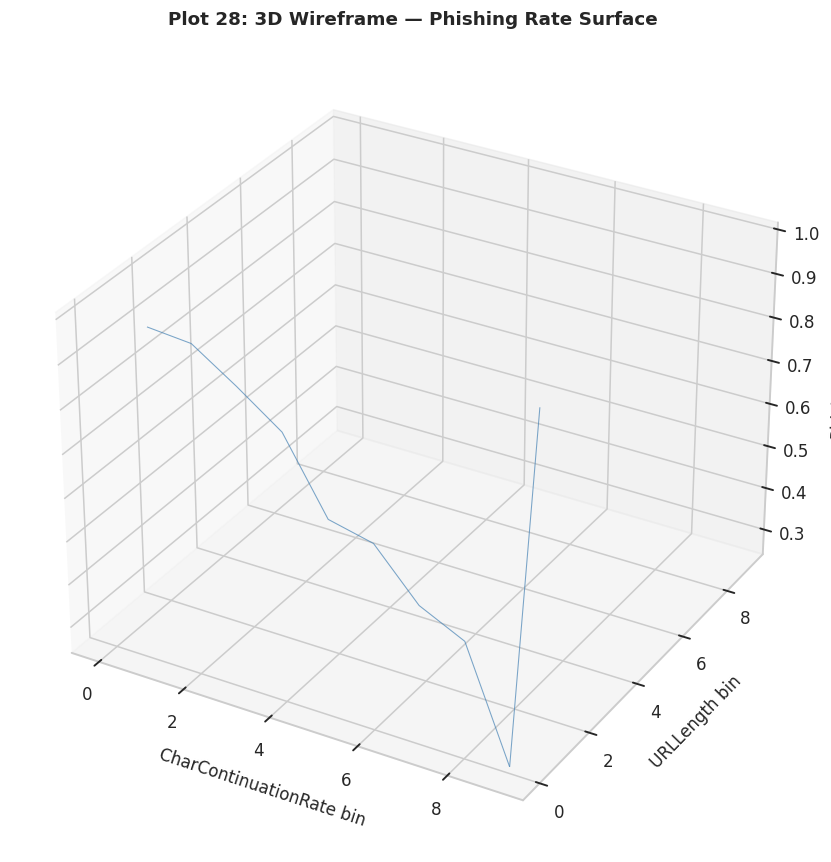

In [37]:
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')
ax.plot_wireframe(Xg, Yg, Z, color='steelblue', linewidth=0.7, alpha=0.7)
ax.set_xlabel('CharContinuationRate bin', labelpad=8)
ax.set_ylabel('URLLength bin', labelpad=8)
ax.set_zlabel('Phishing Rate', labelpad=8)
ax.set_title('Plot 28: 3D Wireframe — Phishing Rate Surface',
             fontsize=12, fontweight='bold', pad=15)
plt.tight_layout(); plt.savefig('plot_28.png', dpi=110, bbox_inches='tight')
plt.show()


**Interpretation:** The wireframe exposes the topology of the same binned observed-rate surface without filled color. The gaps represent feature-bin combinations with fewer than 50 observations. Ridges and valleys summarize variation in this dataset, but they should not be treated as validated classifier decision boundaries.

### Plot 29 — Contour Plots: Phishing Rate (Filled + Line)

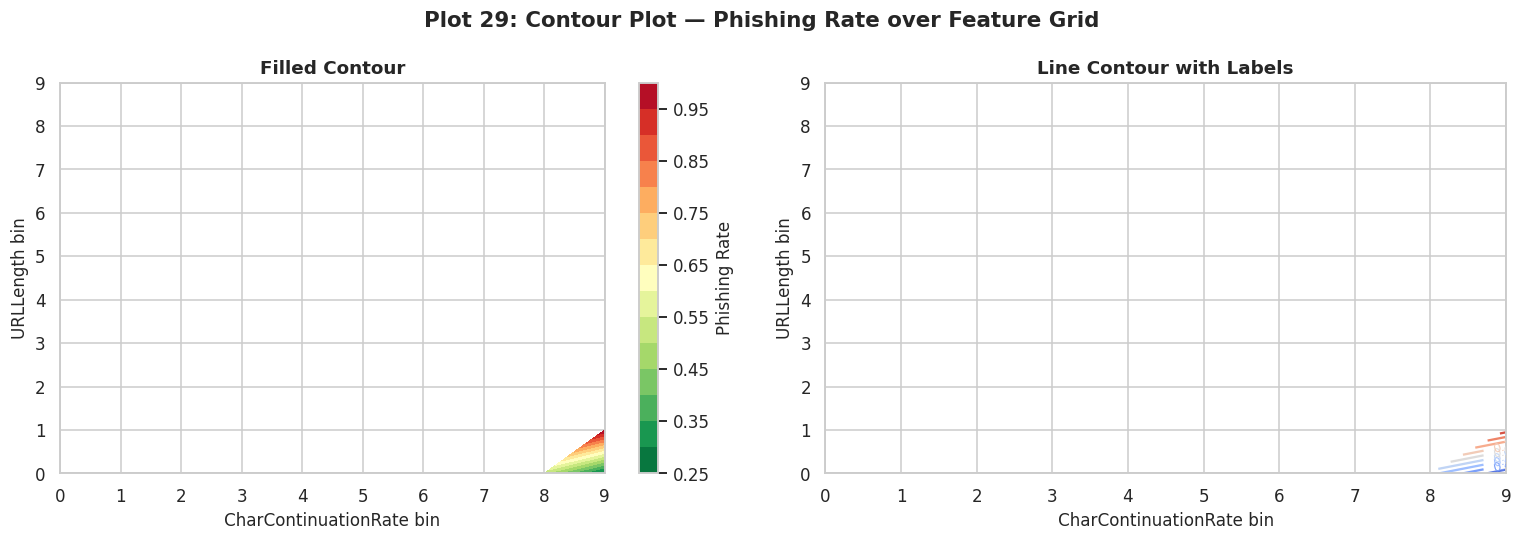

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
cf = ax.contourf(Xg, Yg, Z, levels=15, cmap='RdYlGn_r')
plt.colorbar(cf, ax=ax, label='Phishing Rate')
ax.set_title('Filled Contour', fontsize=12, fontweight='bold')
ax.set_xlabel('CharContinuationRate bin')
ax.set_ylabel('URLLength bin')

ax2 = axes[1]
cs = ax2.contour(Xg, Yg, Z, levels=10, cmap='coolwarm')
ax2.clabel(cs, inline=True, fontsize=8, fmt='%.2f')
ax2.set_title('Line Contour with Labels', fontsize=12, fontweight='bold')
ax2.set_xlabel('CharContinuationRate bin')
ax2.set_ylabel('URLLength bin')

plt.suptitle('Plot 29: Contour Plot — Phishing Rate over Feature Grid',
             fontsize=14, fontweight='bold')
plt.tight_layout(); plt.savefig('plot_29.png', dpi=110, bbox_inches='tight')
plt.show()


**Interpretation:** Contours are a 2D projection of the same observed-rate grid from Plot 27. Filled colors show relative rate levels and labeled lines connect equal values. Because the grid aggregates observed labels, these contours describe sample-level class composition; they are not deployment thresholds and should not be used directly as calibrated risk cutoffs.

### Plot 30 — Triangulation & Mesh Grid Interpolation

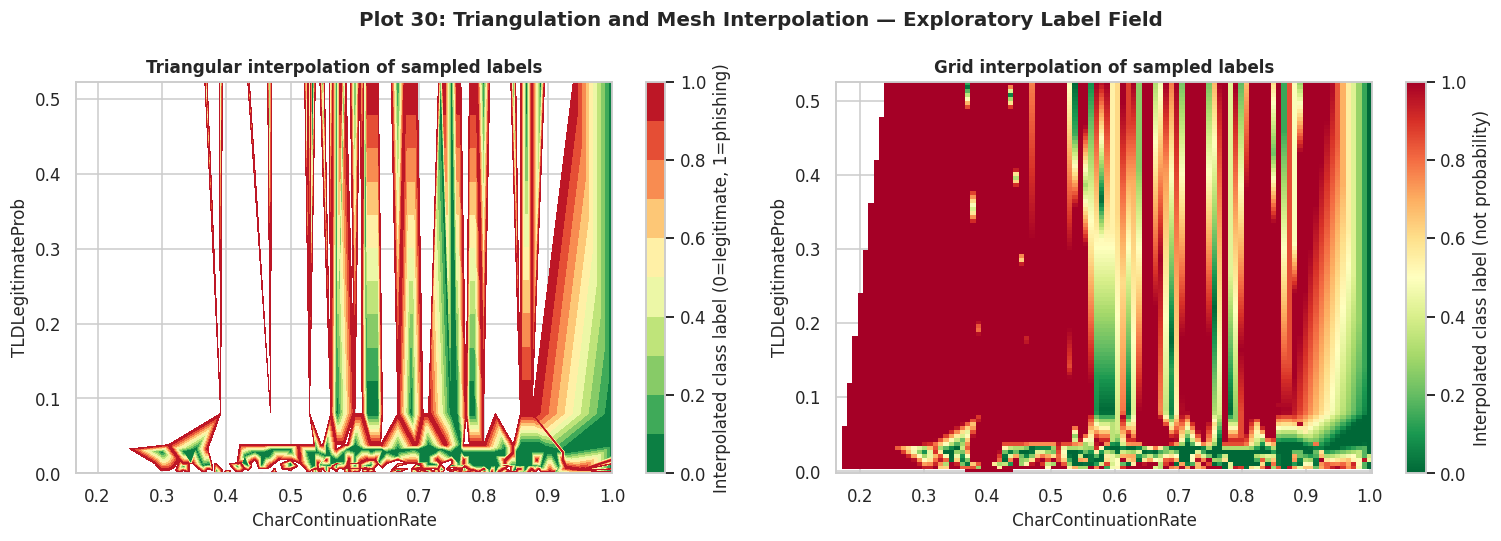

In [39]:
# Plot 30: triangulation/interpolation of sampled class labels — explicitly NOT a rate estimate.
sample_tri = df.sample(n=min(5000, len(df)), random_state=99)
x_pts = sample_tri['CharContinuationRate'].to_numpy()
y_pts = sample_tri['TLDLegitimateProb'].to_numpy()
z_pts = (sample_tri['label'].to_numpy() == 0).astype(float)  # 1=phishing record, 0=legitimate record
triang = tri.Triangulation(x_pts, y_pts)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
tcf = ax.tricontourf(triang, z_pts, levels=np.linspace(0,1,11), cmap='RdYlGn_r')
plt.colorbar(tcf, ax=ax, label='Interpolated class label (0=legitimate, 1=phishing)')
ax.set_title('Triangular interpolation of sampled labels', fontsize=11, fontweight='bold')
ax.set_xlabel('CharContinuationRate'); ax.set_ylabel('TLDLegitimateProb')
ax2 = axes[1]
xi = np.linspace(x_pts.min(), x_pts.max(), 100); yi = np.linspace(y_pts.min(), y_pts.max(), 100)
Xi, Yi = np.meshgrid(xi, yi)
Zi = griddata((x_pts, y_pts), z_pts, (Xi, Yi), method='linear')
im = ax2.pcolormesh(Xi, Yi, Zi, cmap='RdYlGn_r', shading='auto', vmin=0, vmax=1)
plt.colorbar(im, ax=ax2, label='Interpolated class label (not probability)')
ax2.set_title('Grid interpolation of sampled labels', fontsize=11, fontweight='bold')
ax2.set_xlabel('CharContinuationRate'); ax2.set_ylabel('TLDLegitimateProb')
plt.suptitle('Plot 30: Triangulation and Mesh Interpolation — Exploratory Label Field', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.savefig('plot_30.png', bbox_inches='tight'); plt.show()


**Interpretation and limitation:** Triangulation and grid interpolation connect the sampled **binary class labels** in feature space. Intermediate colors arise from mathematical interpolation, not from observed frequencies or a fitted probability model. The plot is included to demonstrate a visualization technique; it must not be described as a phishing probability surface or used to set risk thresholds.

## 7. Plotly Interactive Visualization (Tool 3)

This interactive view adds hover details to the TLD analysis. TLD-level phishing shares are only shown for suffixes with at least 1,000 records so percentages are paired with meaningful sample sizes. This Plotly view supplements the static Matplotlib and Seaborn charts; it does **not** replace the separately required Tableau/Power BI dashboard.

In [40]:
import plotly.express as px

plotly_tld = (df.groupby('TLD', observed=True)
              .agg(records=('label','size'), phishing_share=('label', lambda s: (s == 0).mean()))
              .query('records >= 1000')
              .sort_values('phishing_share', ascending=False)
              .reset_index())
plotly_tld['phishing_percent'] = 100 * plotly_tld['phishing_share']
fig = px.bar(
    plotly_tld,
    x='TLD', y='phishing_percent', color='phishing_percent',
    hover_data={'records':':,', 'phishing_percent':':.1f', 'phishing_share':False},
    color_continuous_scale='Reds',
    title='Plot 31: Interactive Phishing Share by TLD (≥1,000 records)',
    labels={'TLD':'Top-level domain', 'phishing_percent':'Phishing share (%)', 'records':'Records'}
)
fig.update_layout(template='plotly_white', xaxis_tickangle=-45,
                  coloraxis_colorbar_title='Phishing %', yaxis_range=[0,105],
                  title_x=0.02, margin=dict(l=45,r=25,t=70,b=90))
fig.show()


## 8. Findings, limitations, and dashboard handoff

### Evidence-backed findings from this supplied CSV
- **Class composition:** 134,850 legitimate records (57.2%) and 100,945 phishing records (42.8%).
- **URL length:** the median is 34 characters for phishing records versus 26 for legitimate records; in defined bins, the phishing share rises sharply for lengths of 50 characters and above in this dataset.
- **Page structure:** median `LineOfCode` is 12 for phishing versus 1,105 for legitimate; median external references are 0 versus 46.
- **Metadata:** `HasTitle` occurs in 99.9% of legitimate records and 67.8% of phishing records; `HasCopyrightInfo` occurs in 80.8% versus 5.7%.
- **Feature caution:** all legitimate records in this file have `URLSimilarityIndex = 100`. Its exact provenance should be checked before predictive use; a strong in-dataset association is not by itself proof of target leakage.

### Limitations
- The notebook presents descriptive analysis, not a trained, validated detector; no accuracy or deployment claims are made.
- URLs/domains repeat. For any future model, split by URL/domain or otherwise prevent related records crossing evaluation partitions.
- TLD patterns and precomputed webpage features may be dataset-specific and may drift over time.
- Several visualizations use deterministic samples or restricted axis ranges for legibility; their captions identify those views.
- Plot 30 interpolates binary labels and is shown only as a visualization-method demonstration, not as a probability or risk surface.

### Power BI dashboard handoff (rubric requirement)
A native Power BI deliverable should include KPI cards for total URLs, phishing share and legitimate share; a class-distribution chart; TLD phishing-share chart with record counts; feature comparison visuals; and slicers for class, TLD and URL-length bin. Test that slicers affect the intended visuals, save the `.pbix` project and include a screenshot in the presentation. The notebook and its Plotly chart are supporting artifacts, not substitutes for the `.pbix`.

### Final conclusion
The dataset contains meaningful descriptive differences in URL structure, webpage complexity and selected metadata between the two labels. These differences support the case study's visualization objectives, but they should be communicated as dataset-specific associations and validated on independent, time-appropriate data before being used for operational security decisions.
